<a href="https://colab.research.google.com/github/narayankarrahe/APPLIANCES-ENERGY-PREDICTION-USING-MACHINE-LEARNING-DEEP-LEARNING/blob/main/Appliances_Energy_Prediction_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
1. #Initial Data Cleaning and Transformation - Data Preprocessing
#Import and load original file
import pandas as pd
import numpy as np

df = pd.read_excel("/content/Appliances Energy Prediciton.xlsx")

print("Original Shape:", df.shape)
df.head()

Original Shape: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [ ]:
2. ##basic information
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Columns:
['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']

Data Types:
date           datetime64[ns]
Appliances              int64
lights                  int64
T1                    float64
RH_1                  float64
T2                    float64
RH_2                  float64
T3                    float64
RH_3                  float64
T4                    float64
RH_4                  float64
T5                    float64
RH_5                  float64
T6                    float64
RH_6                  float64
T7                    float64
RH_7                  float64
T8                    float64
RH_8                  float64
T9                    float64
RH_9                  float64
T_out                 float64
Press_mm_hg           float64
RH_out                float64
Windspeed  

In [ ]:
3.#Check missing values
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

Missing Values:
date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

Total Missing Values: 0


In [ ]:
4. #Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:
5. #Remove unwanted columns
df.drop(['rv1', 'rv2'], axis=1, inplace=True)

In [ ]:
6. #Check constant columns
for column in df.columns:
    if df[column].nunique() == 1:
        print("Constant column:", column)

In [ ]:
7. #Create useful new columns
df['Month'] = df['date'].dt.month
df['Hour'] = df['date'].dt.hour

In [ ]:
8. #remove original date
df.drop('date', axis=1 , inplace=True)

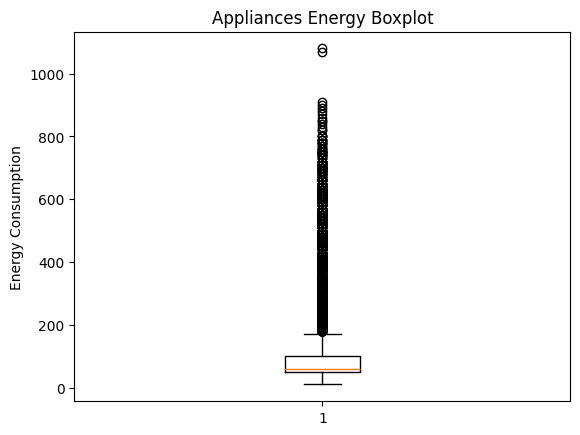

In [ ]:
9. #Check outliers & Cap extreme values
import matplotlib.pyplot as plt

plt.boxplot(df['Appliances'])
plt.title("Appliances Energy Boxplot (Before Capping)")
plt.ylabel("Energy Consumption")
plt.show()

# Cap extreme target outliers at 99th percentile (Windsorization)
# This prevents rare extreme spikes from penalizing models quadratically
cap_limit = df['Appliances'].quantile(0.99)
print(f"99th Percentile Cap Limit for Appliances: {cap_limit:.2f}")
df['Appliances'] = df['Appliances'].clip(upper=cap_limit)
print("Outlier capping applied successfully!")

In [ ]:
10. #Final preprocessing check
print("Final Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Final Shape: (19735, 28)

Missing Values:
0

Duplicate Rows:
0


In [ ]:
11. #View Final data
df.head()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,Month,Hour
0,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,1,17
1,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,1,17
2,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,1,17
3,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,1,17
4,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,1,17


In [ ]:
12.#Save updated excel
output_file = "Updated_Appliances_Energy_Prediction.xlsx"

df.to_excel(output_file, index=False)

print("Updated Appliances Energy Prediction file created successfully!")

Updated Appliances Energy Prediction file created successfully!


In [ ]:
13. #Download updated Excel
from google.colab import files

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
14. #EDA
#Load the updated dataset
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("/content/Updated_Appliances_Energy_Prediction.xlsx")

print(df.shape)
df.head()

(19735, 28)


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,Month,Hour
0,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,1,17
1,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,1,17
2,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,1,17
3,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,1,17
4,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,1,17


In [ ]:
15. #Descriptive statistics
df.describe()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,Month,Hour
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,3.101647,11.502002
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,1.339200,6.921953
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,1.000000,0.000000
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,2.000000,6.000000
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,3.000000,12.000000
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,4.000000,17.000000
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,5.000000,23.000000


In [ ]:
16. #Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 28 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Appliances   19735 non-null  int64  
 1   lights       19735 non-null  int64  
 2   T1           19735 non-null  float64
 3   RH_1         19735 non-null  float64
 4   T2           19735 non-null  float64
 5   RH_2         19735 non-null  float64
 6   T3           19735 non-null  float64
 7   RH_3         19735 non-null  float64
 8   T4           19735 non-null  float64
 9   RH_4         19735 non-null  float64
 10  T5           19735 non-null  float64
 11  RH_5         19735 non-null  float64
 12  T6           19735 non-null  float64
 13  RH_6         19735 non-null  float64
 14  T7           19735 non-null  float64
 15  RH_7         19735 non-null  float64
 16  T8           19735 non-null  float64
 17  RH_8         19735 non-null  float64
 18  T9           19735 non-null  float64
 19  RH_9

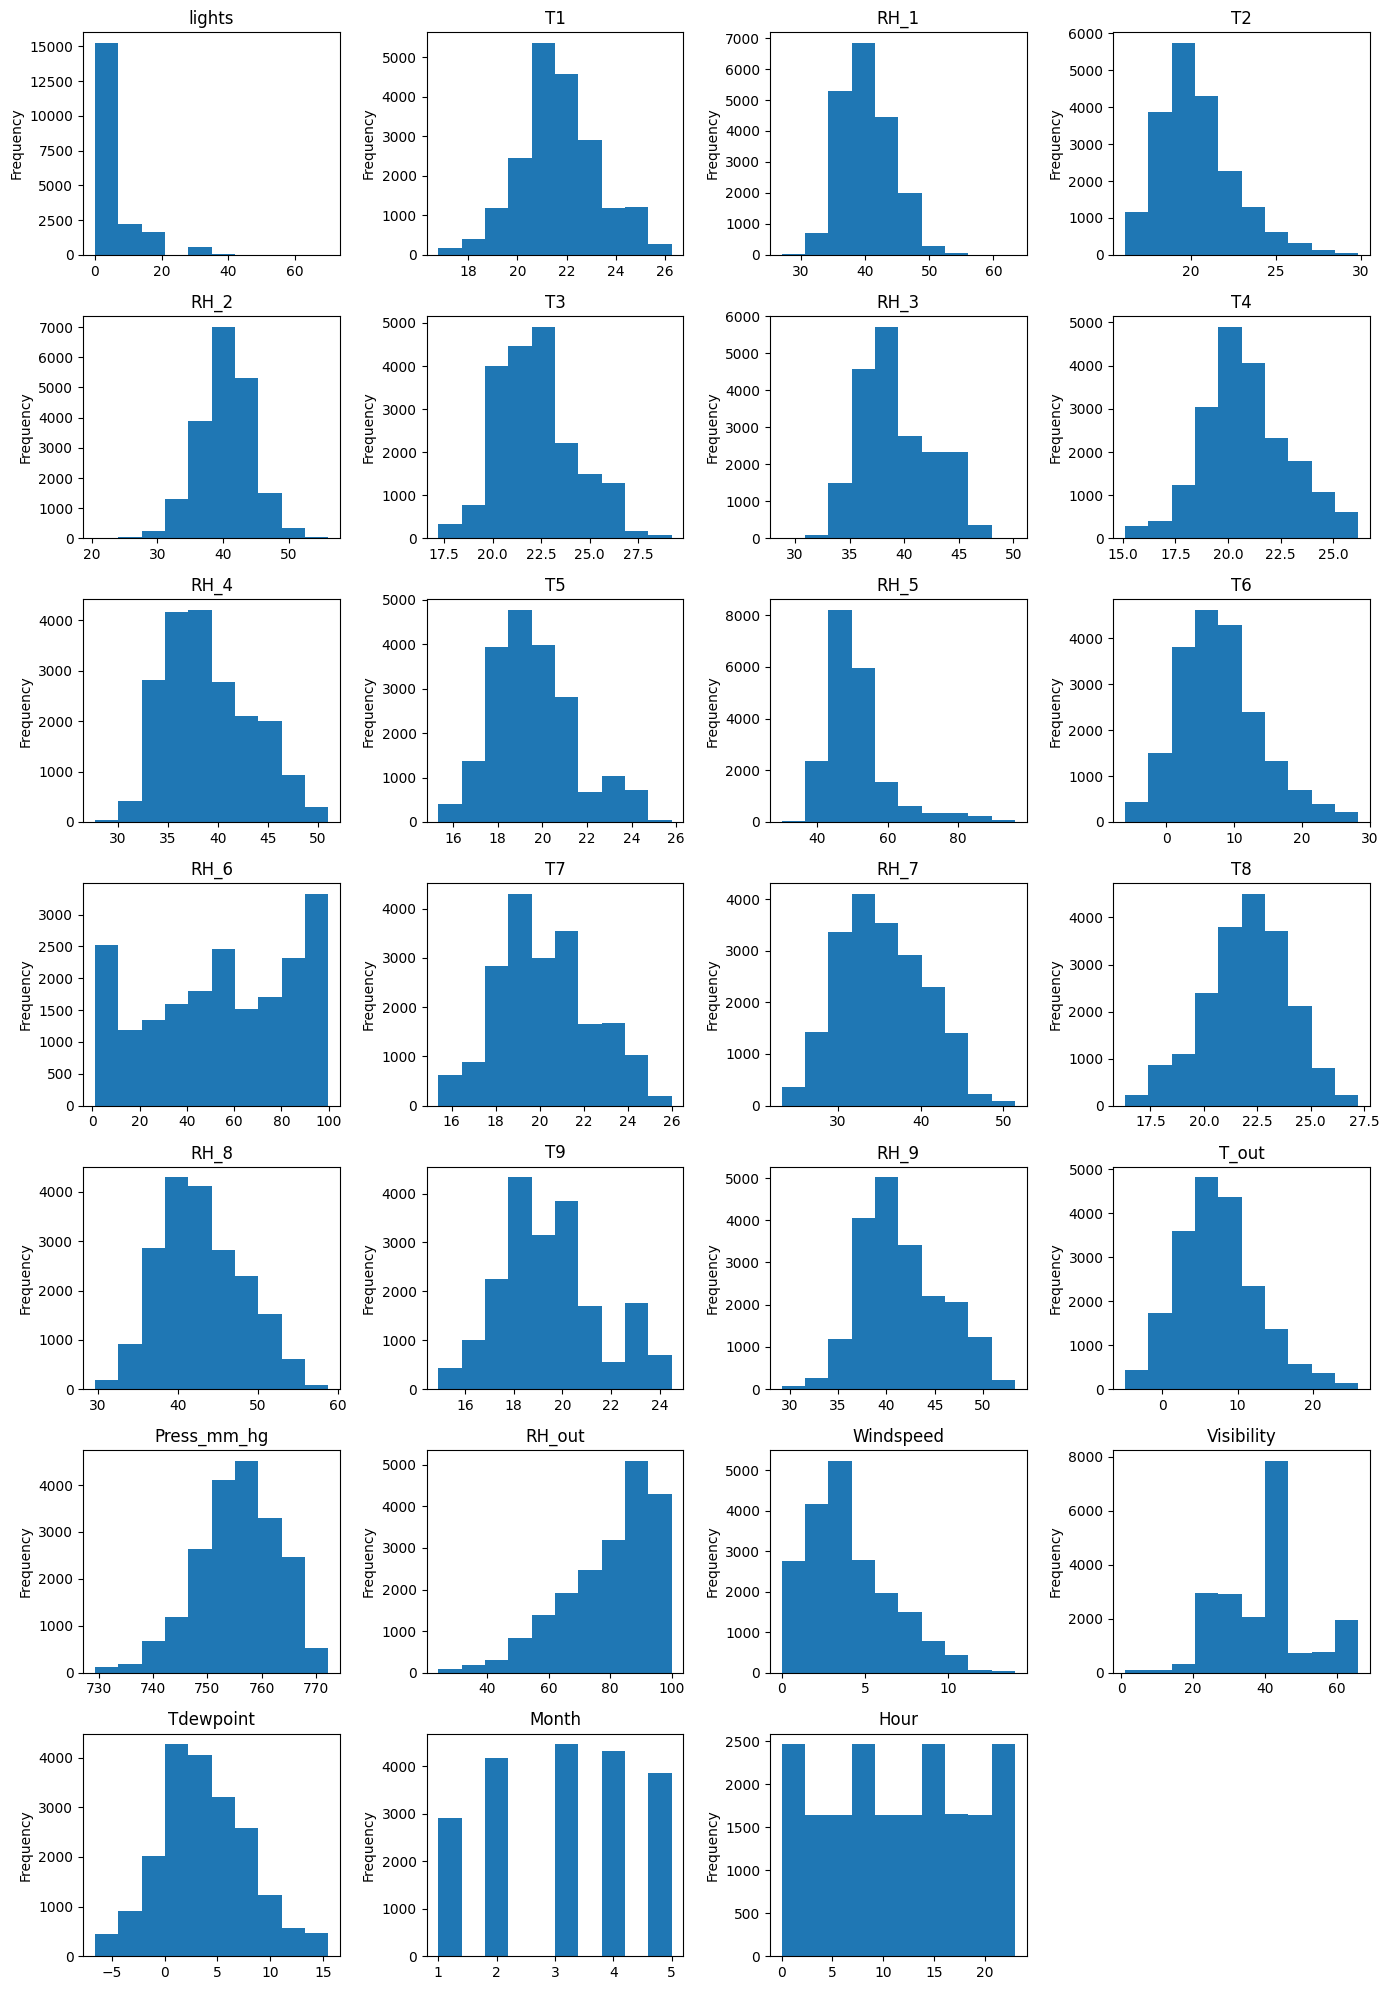

In [ ]:
17. # Distribution plots for all columns
import matplotlib.pyplot as plt

columns = df.select_dtypes(include='number').drop(columns='Appliances').columns

fig, ax = plt.subplots(7, 4, figsize=(14, 20))
ax = ax.flatten()

for i, col in enumerate(columns):
    df[col].plot(kind='hist', bins=10, ax=ax[i])
    ax[i].set_title(col)
    ax[i].grid(False)

for i in range(len(columns), len(ax)):
  ax[i].axis('off')

plt.tight_layout()
plt.show()

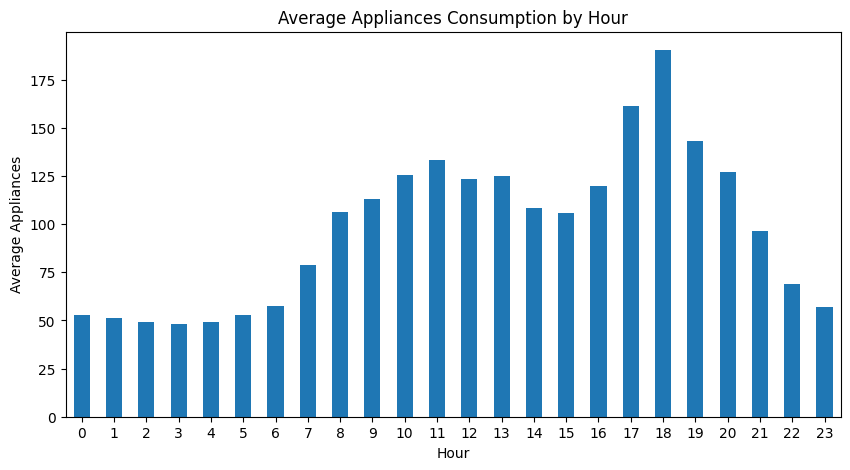

In [ ]:
18. #Bar plot
# Average Appliances consumption by hour
df.groupby('Hour')['Appliances'].mean().plot(kind='bar', figsize=(10,5))

plt.title('Average Appliances Consumption by Hour')
plt.xlabel('Hour')
plt.ylabel('Average Appliances')
plt.xticks(rotation=0)
plt.show()

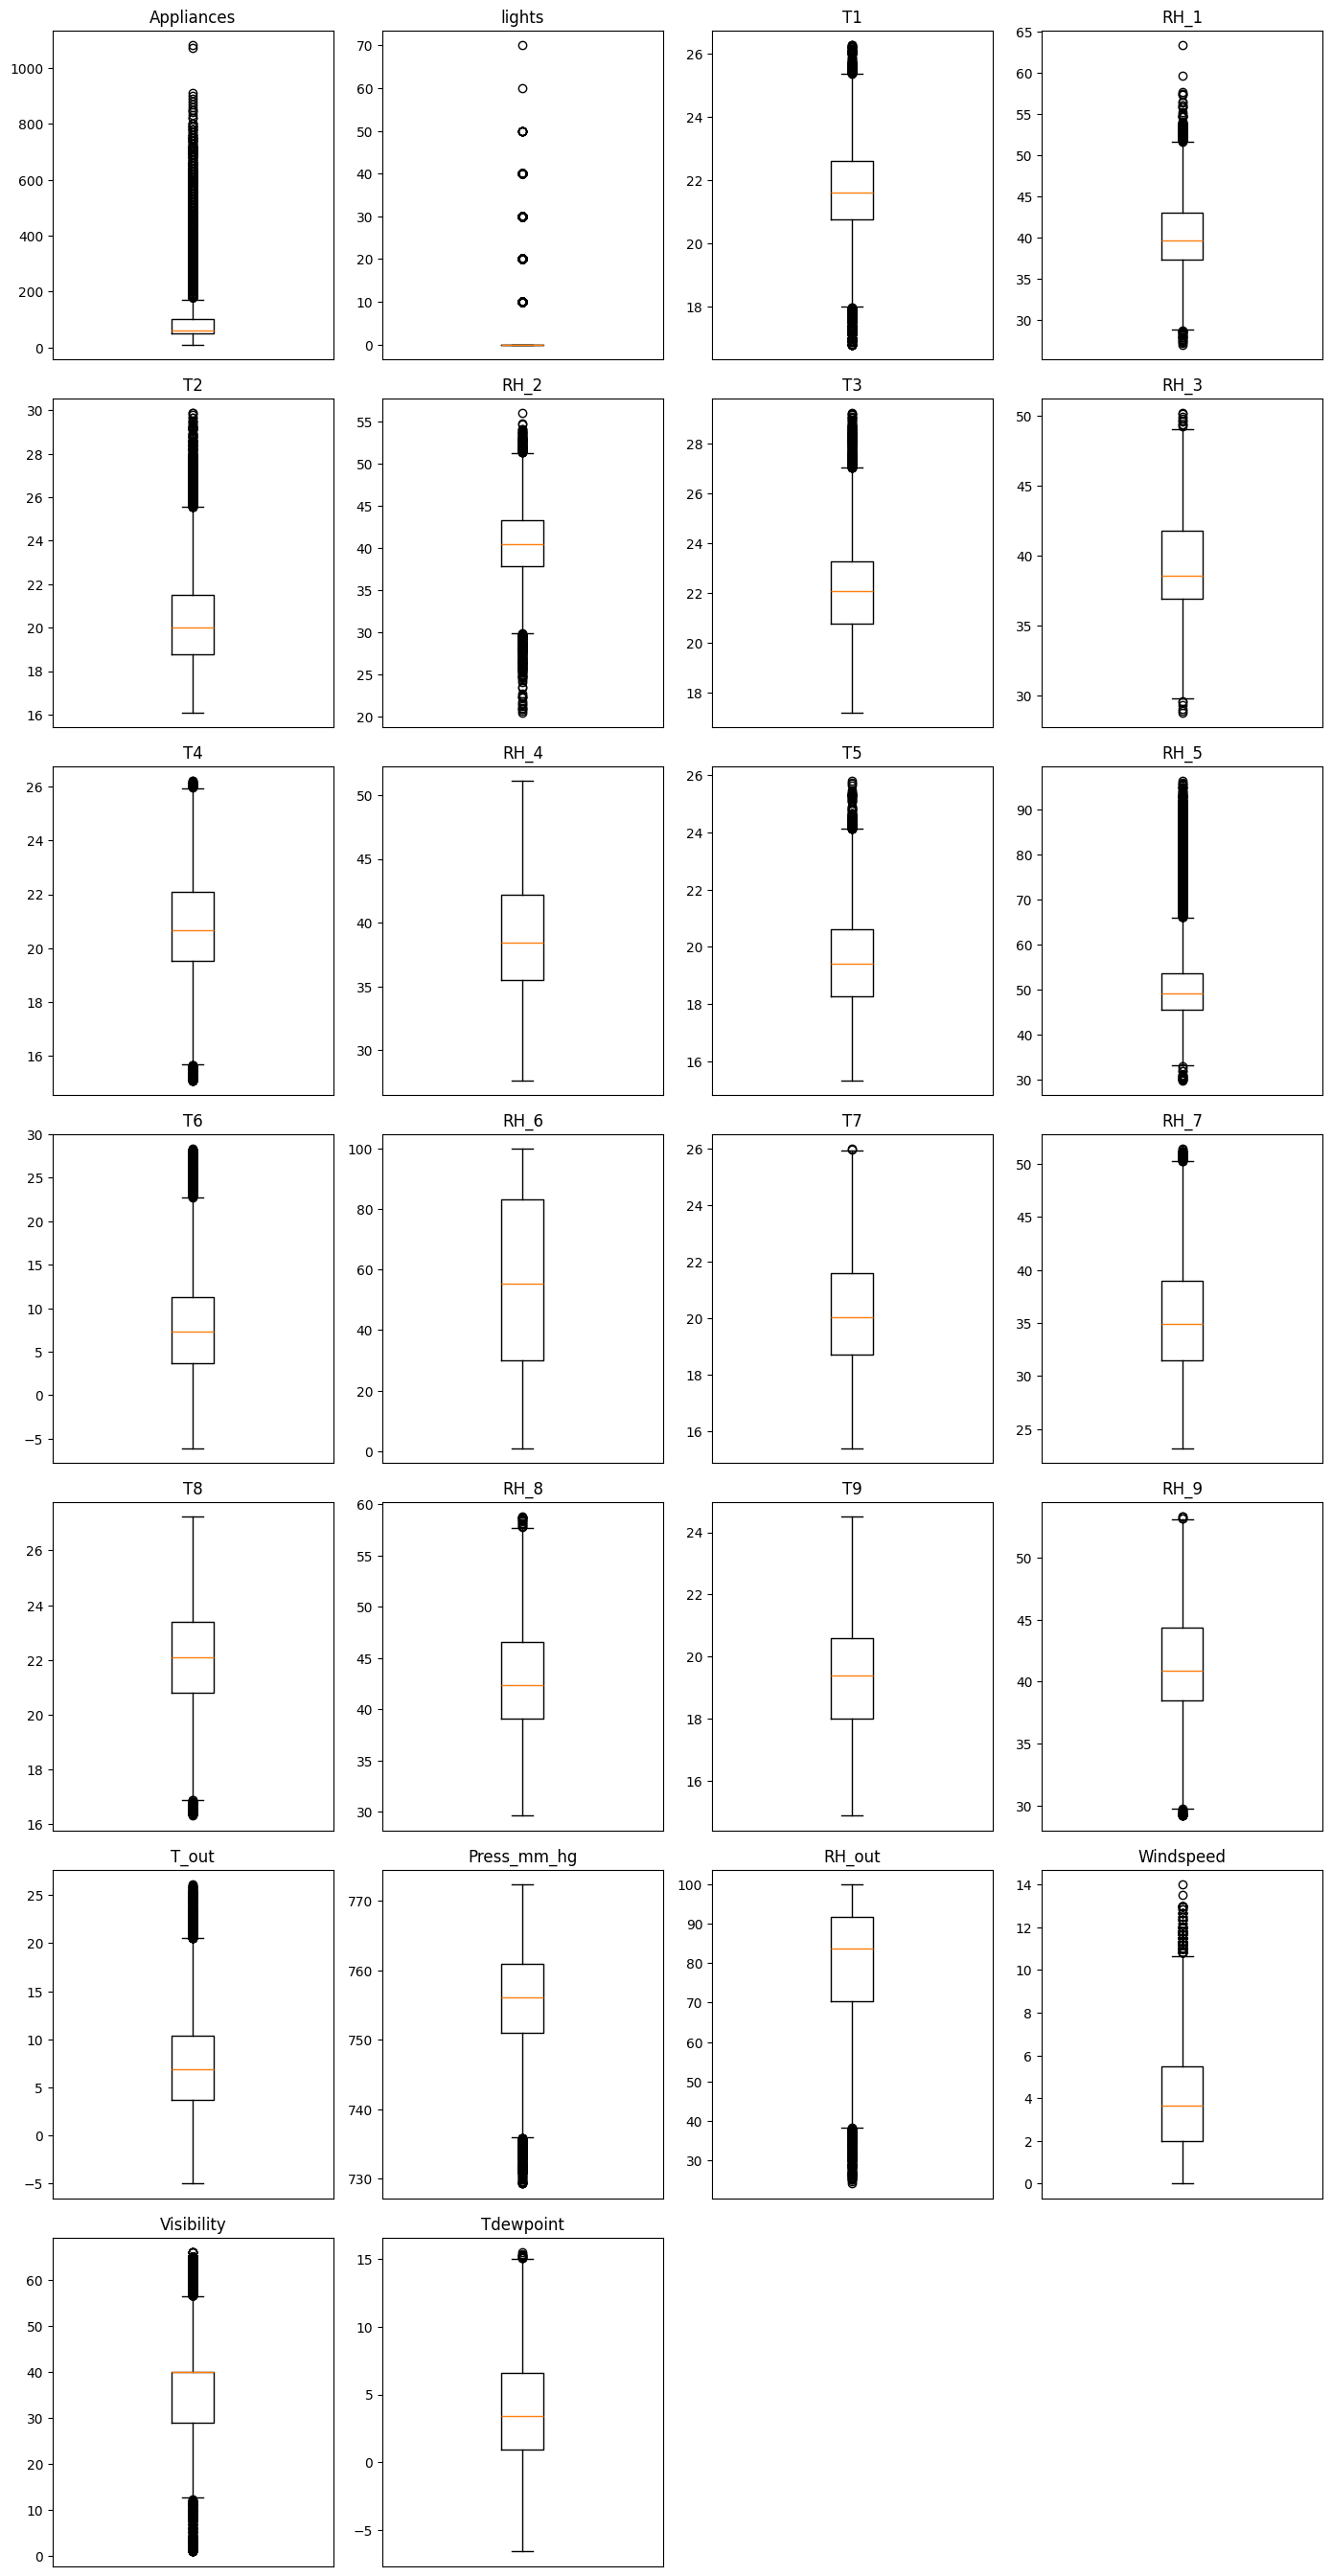

In [ ]:
19. # Box plots for continuous numerical columns

columns = df.select_dtypes(include='number').columns
columns = columns.drop(['Month', 'Hour'])

fig, ax = plt.subplots(7, 4, figsize=(14, 27))
ax = ax.flatten()

for i, col in enumerate(columns):
    ax[i].boxplot(df[col].dropna())
    ax[i].set_title(col)
    ax[i].set_xticks([])

# Remove empty plots
for i in range(len(columns), len(ax)):
    ax[i].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
20. # Check number of outliers in each column

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]

    print(col, ":", len(outliers))

Appliances : 2138
lights : 4483
T1 : 515
RH_1 : 146
T2 : 546
RH_2 : 235
T3 : 217
RH_3 : 15
T4 : 186
RH_4 : 0
T5 : 179
RH_5 : 1330
T6 : 513
RH_6 : 0
T7 : 2
RH_7 : 42
T8 : 71
RH_8 : 17
T9 : 0
RH_9 : 21
T_out : 436
Press_mm_hg : 219
RH_out : 239
Windspeed : 214
Visibility : 2522
Tdewpoint : 10


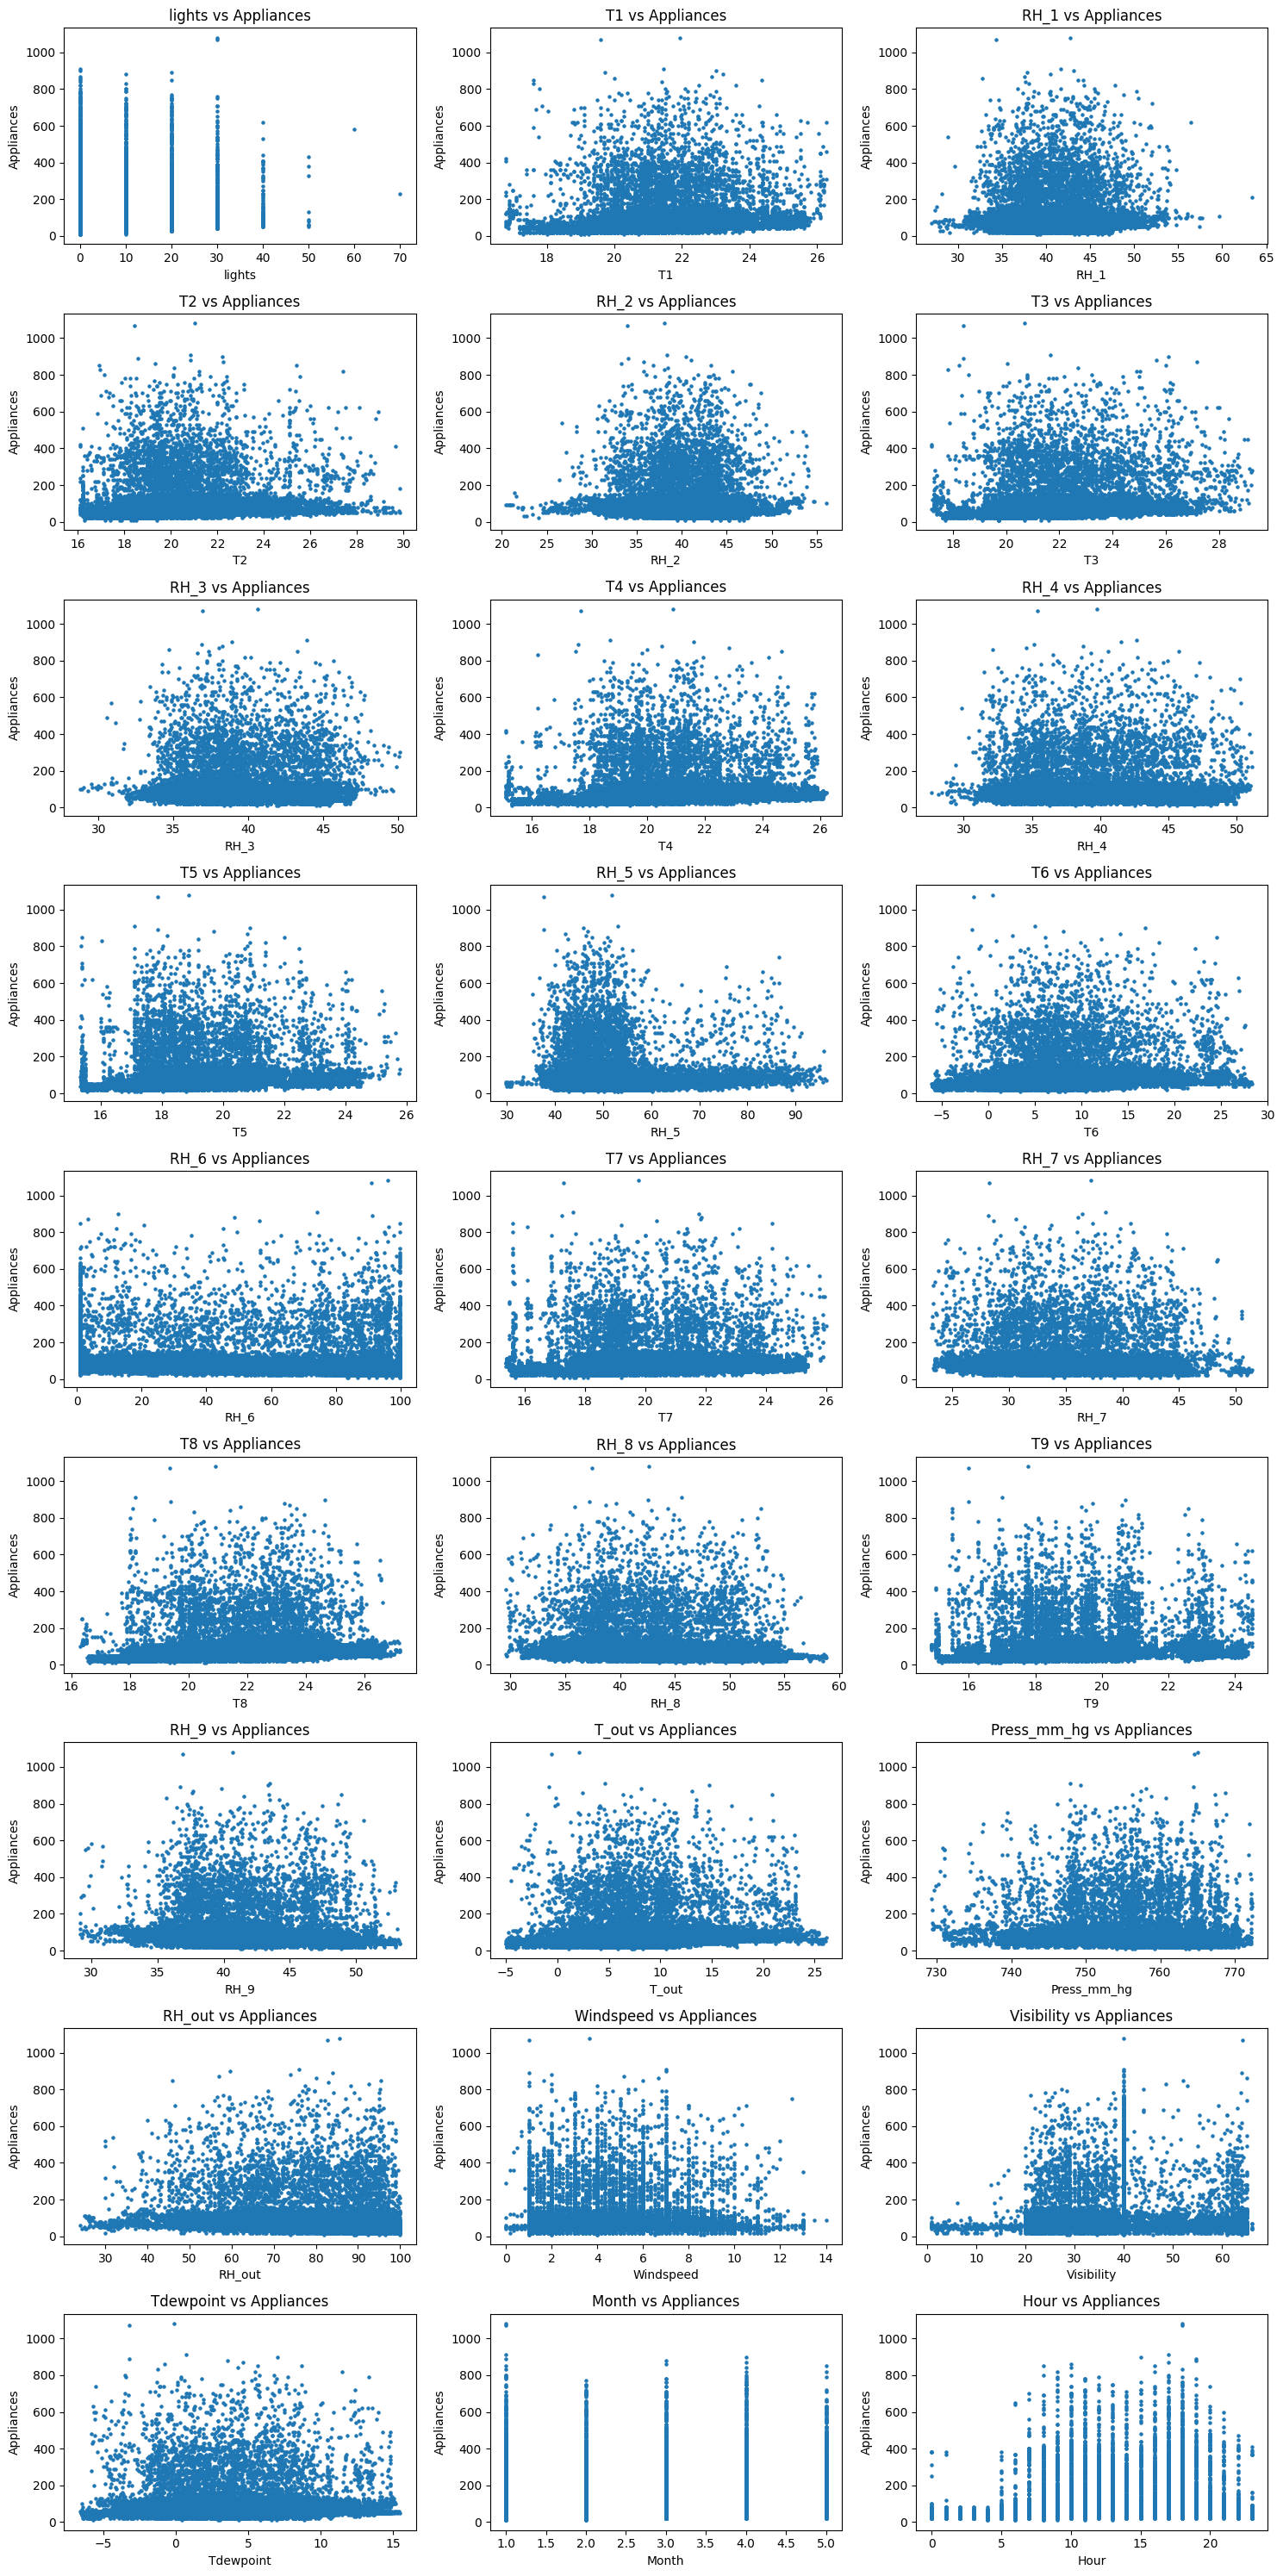

In [ ]:
21. # Scatter plots for all numerical columns vs Appliances

columns = df.select_dtypes(include='number').columns.drop('Appliances')

fig, ax = plt.subplots(9, 3, figsize=(15, 30))
ax = ax.flatten()

for i, col in enumerate(columns):
    ax[i].scatter(df[col], df['Appliances'], s=5)
    ax[i].set_title(col + ' vs Appliances')
    ax[i].set_xlabel(col)
    ax[i].set_ylabel('Appliances')

plt.tight_layout()
plt.show()

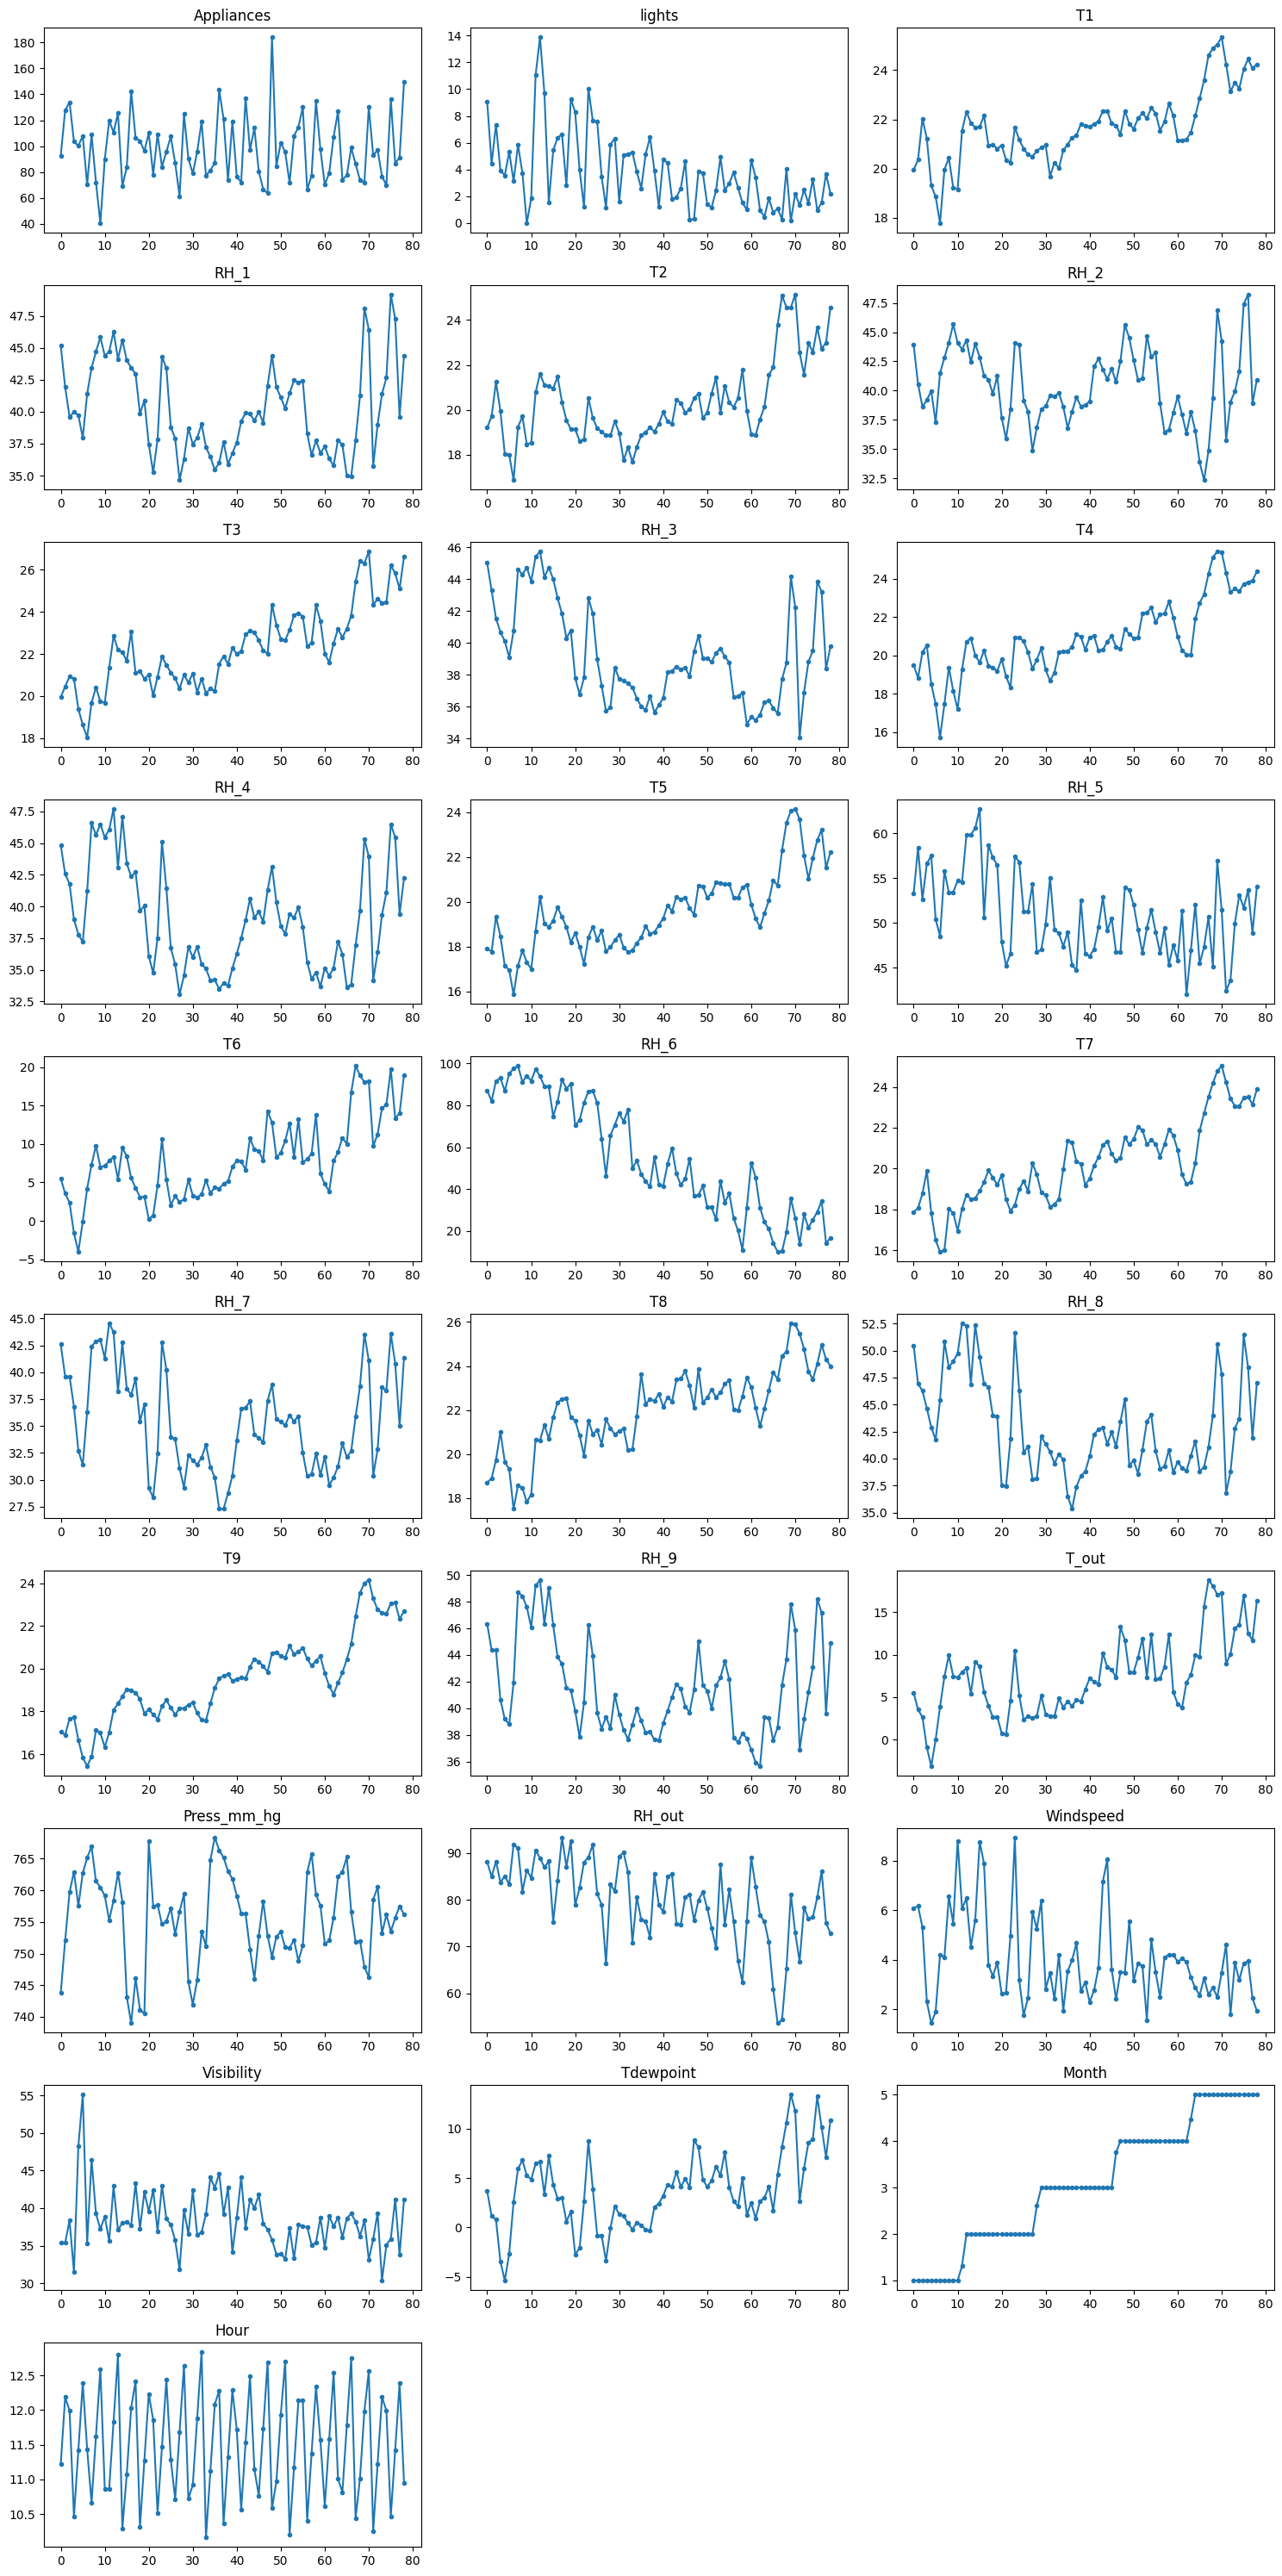

In [ ]:
22. #Line plots for all columns
import matplotlib.pyplot as plt

columns = df.select_dtypes(include='number').loc[:, df.select_dtypes(include='number').nunique() > 2].columns

fig, ax = plt.subplots(10, 3, figsize=(15, 30))
ax = ax.flatten()

for i, col in enumerate(columns):
    df[col].groupby(df.index // 250).mean().plot(ax=ax[i], marker='o', markersize=3)
    ax[i].set_title(col)
    ax[i].set_xlabel('')
    ax[i].set_ylabel('')
    ax[i].grid(False)

for i in range(len(columns), len(ax)):
    ax[i].set_visible(False)

plt.tight_layout()
plt.show()

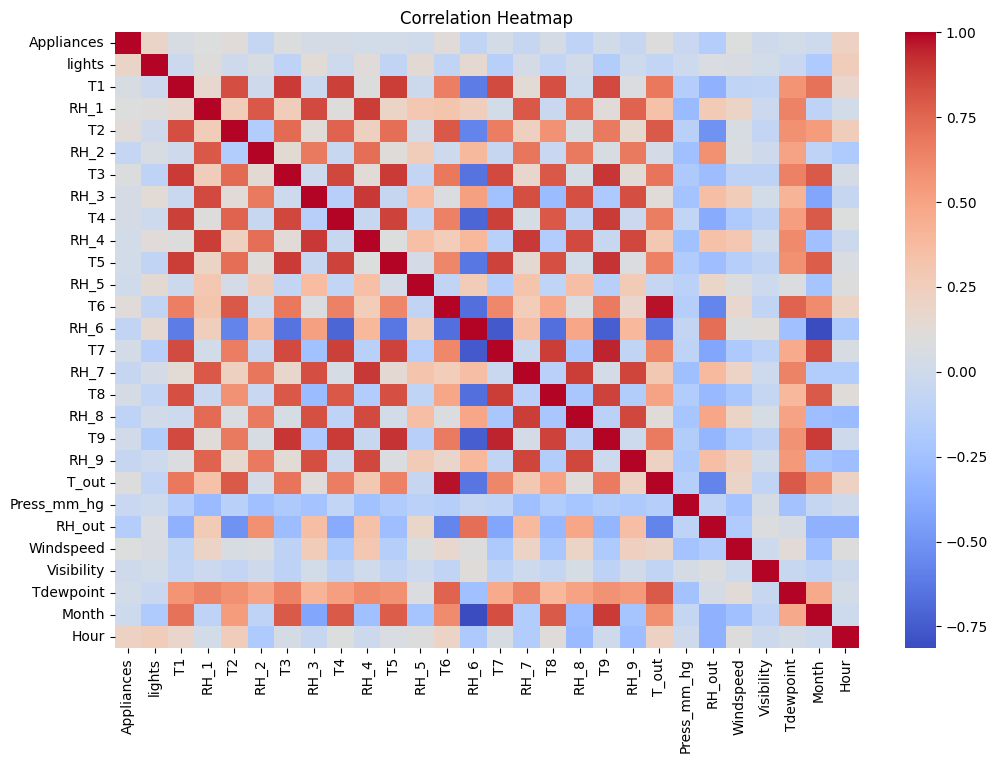

In [ ]:
23. #Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
24. #correlation with target
correlation = df.corr(numeric_only=True)['Appliances']

print(correlation.sort_values(ascending=False))

Appliances     1.000000
Hour           0.216792
lights         0.197278
T2             0.120073
T6             0.117638
T_out          0.099155
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
T1             0.055447
T4             0.040281
T8             0.039572
RH_3           0.036292
T7             0.025801
T5             0.019760
RH_4           0.016965
Tdewpoint      0.015353
T9             0.010010
RH_5           0.006955
Visibility     0.000230
Month         -0.011606
Press_mm_hg   -0.034885
RH_9          -0.051462
RH_7          -0.055642
RH_2          -0.060465
RH_6          -0.083178
RH_8          -0.094039
RH_out        -0.152282
Name: Appliances, dtype: float64


In [ ]:
25.# Train-test split
from sklearn.model_selection import train_test_split

# Regression algorithms
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR

# Feature scaling
from sklearn.preprocessing import StandardScaler

# Evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

# Actual vs Predicted visualization
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
26. # Separate input features and target variable
X = df.drop('Appliances', axis=1)
y = df['Appliances']

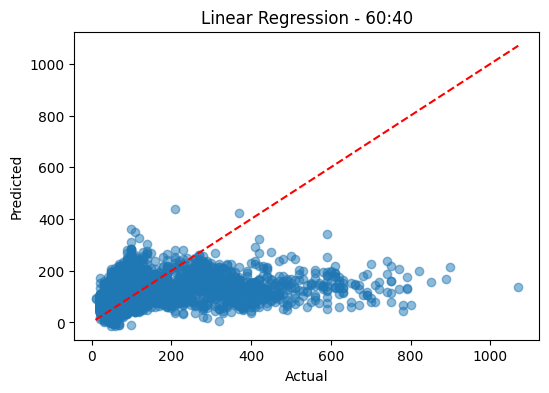

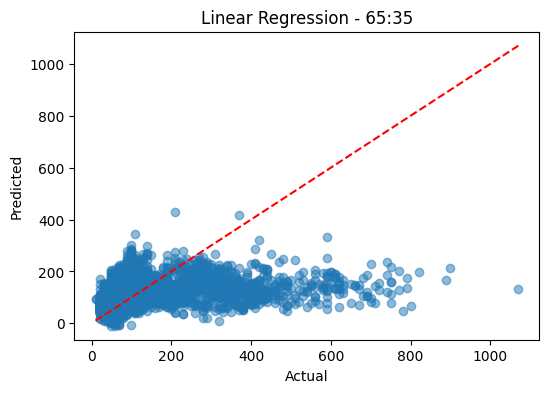

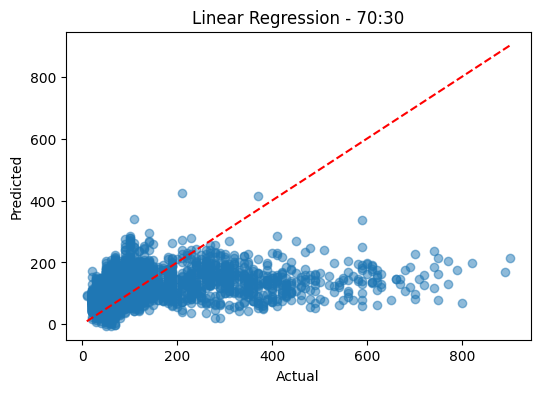

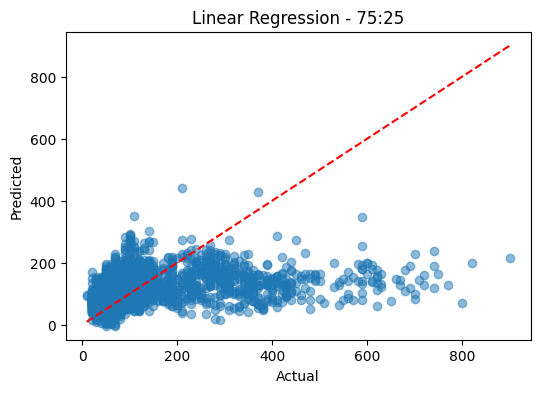

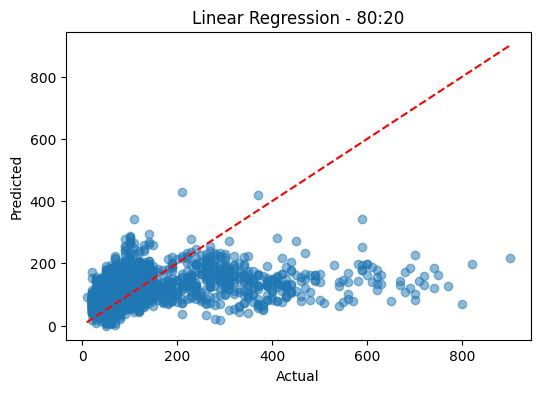

,Split,RMSE,MAE,MAPE,R²
0,60:40,95.481867,53.543218,0.610058,0.155064
1,65:35,95.307674,53.549823,0.615279,0.159190
2,70:30,92.407915,52.893719,0.622646,0.171160
3,75:25,91.218336,52.732544,0.626483,0.162382
4,80:20,91.010986,52.511302,0.628945,0.172287


In [ ]:
27. # Linear Regression - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred),
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Linear Regression - {split_name}")
    plt.show()

linear_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(linear_results)

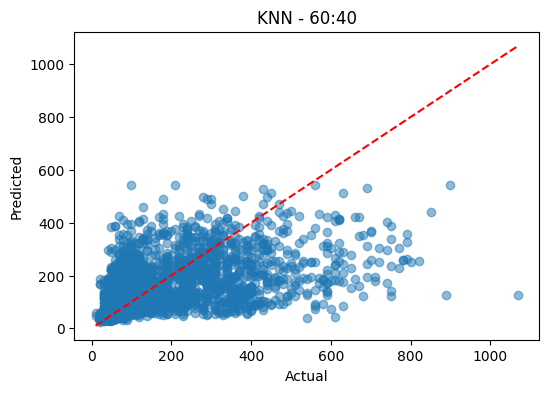

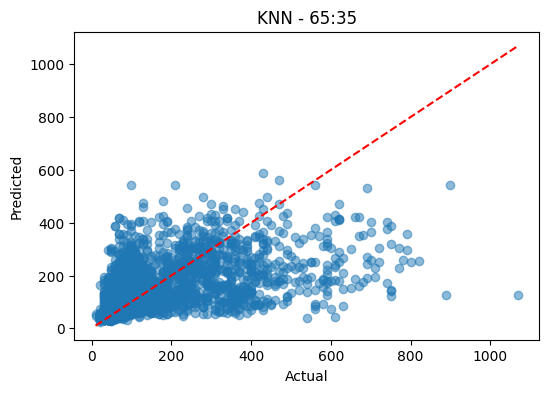

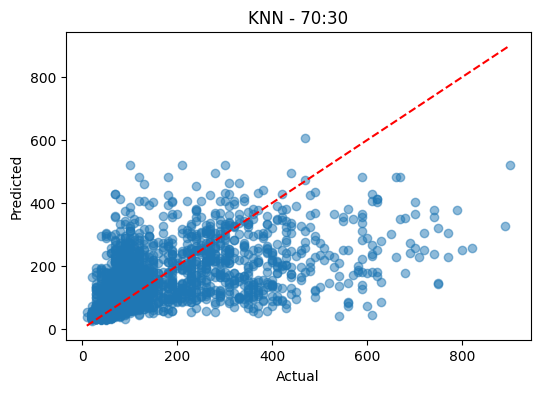

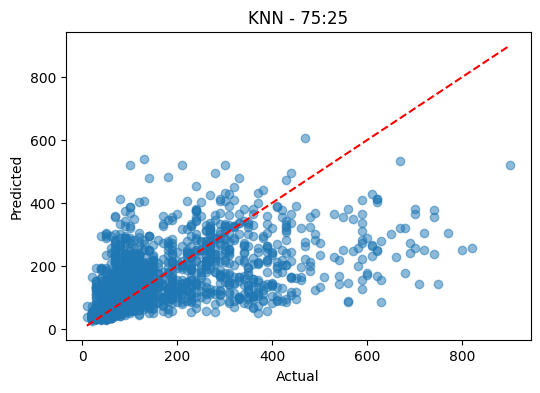

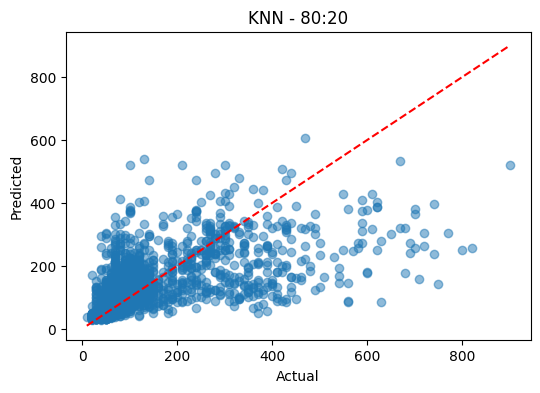

,Split,RMSE,MAE,MAPE,R²
0,60:40,79.333456,37.112997,0.343043,0.416696
1,65:35,79.455800,36.751592,0.340084,0.415623
2,70:30,75.970425,35.384226,0.333749,0.439802
3,75:25,73.982486,34.486826,0.328603,0.449015
4,80:20,73.267701,33.987332,0.326007,0.463565


In [ ]:
28. # KNN Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = KNeighborsRegressor(n_neighbors=5)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred),
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"KNN - {split_name}")
    plt.show()

knn_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(knn_results)

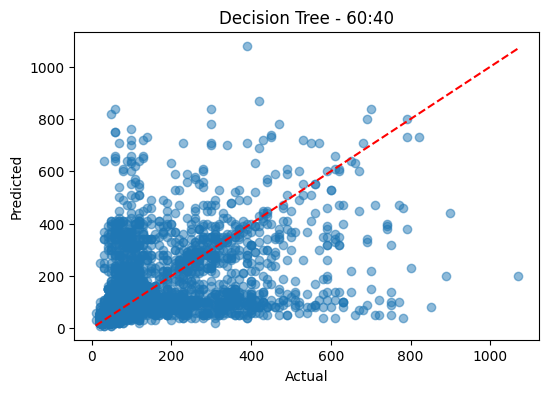

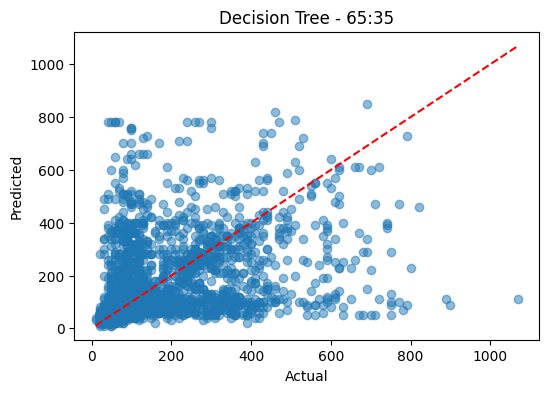

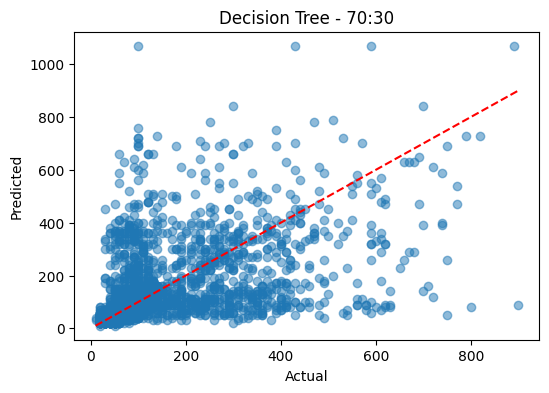

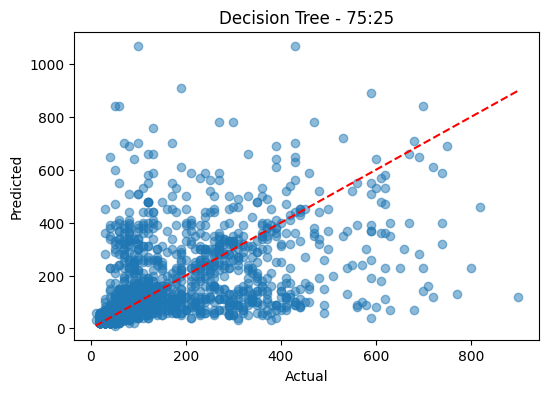

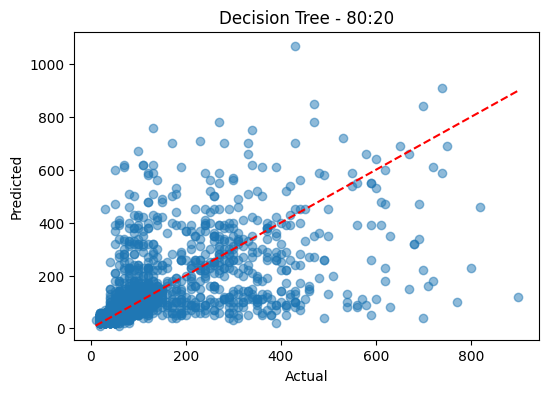

,Split,RMSE,MAE,MAPE,R²
0,60:40,96.324590,40.880416,0.376616,0.140083
1,65:35,97.480344,40.511002,0.372568,0.120418
2,70:30,92.523134,39.096436,0.359865,0.169092
3,75:25,89.756460,36.963924,0.347204,0.189014
4,80:20,87.251184,36.189511,0.322008,0.239263


In [ ]:
29. # Decision Tree Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    model = DecisionTreeRegressor(random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred),
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Decision Tree - {split_name}")
    plt.show()

decision_tree_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(decision_tree_results)

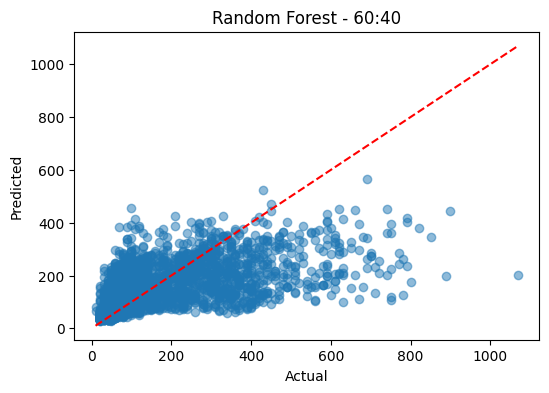

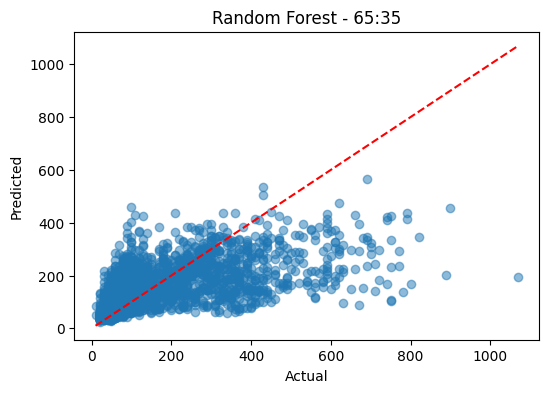

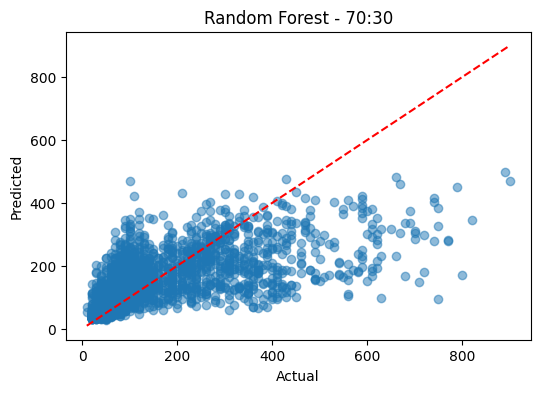

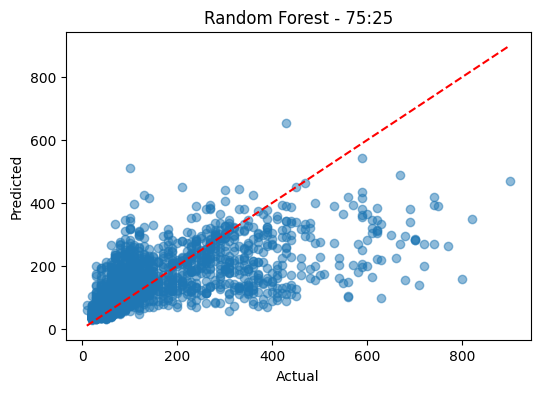

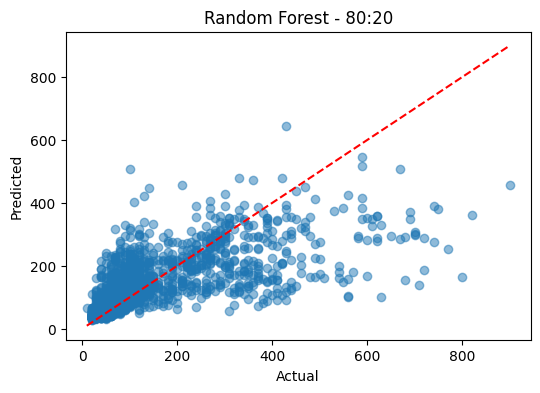

,Split,RMSE,MAE,MAPE,R²
0,60:40,74.614119,35.418578,0.345165,0.484030
1,65:35,73.798481,34.772239,0.339270,0.495876
2,70:30,69.526212,33.406805,0.335422,0.530809
3,75:25,68.147037,32.542538,0.328542,0.532506
4,80:20,67.526327,31.973516,0.323495,0.544343


In [ ]:
30. # Random Forest Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred),
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Random Forest - {split_name}")
    plt.show()

random_forest_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(random_forest_results)


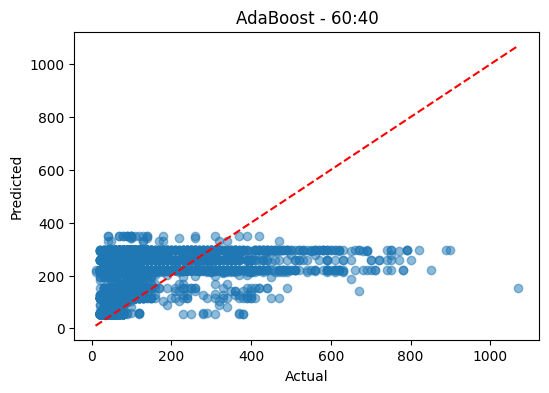

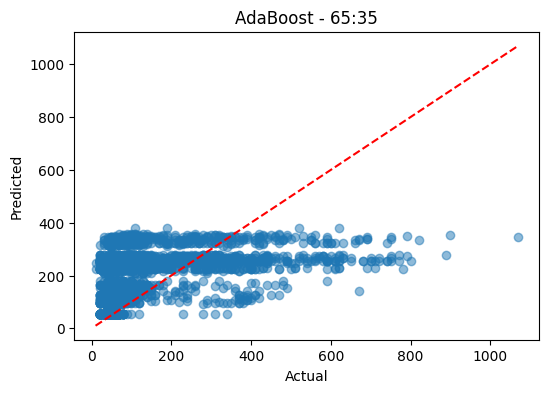

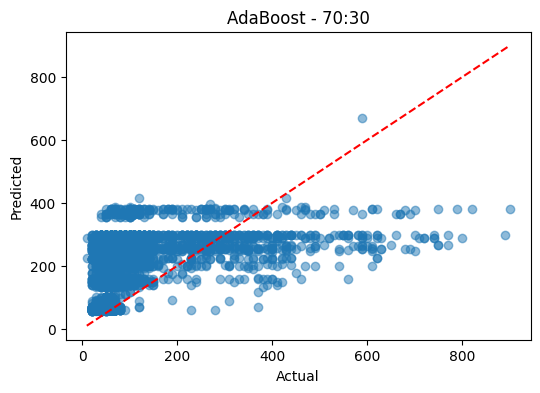

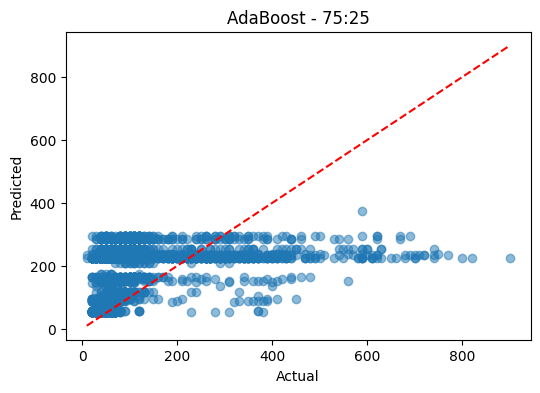

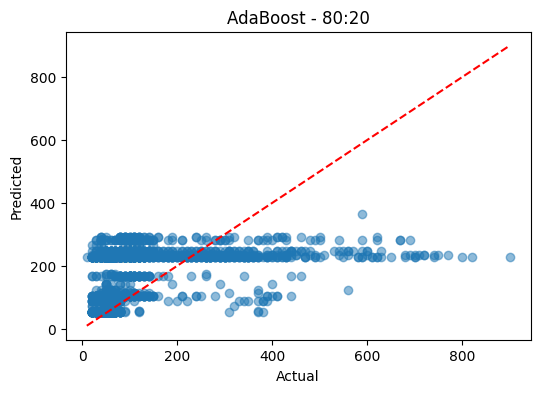

,Split,RMSE,MAE,MAPE,R²
0,60:40,130.931443,99.761897,1.490058,-0.588803
1,65:35,137.809856,106.094685,1.603245,-0.757935
2,70:30,145.978304,117.232968,1.828028,-1.068373
3,75:25,123.908250,93.483312,1.401144,-0.545548
4,80:20,123.863760,93.145622,1.395978,-0.533136


In [ ]:
31. # AdaBoost Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    model = AdaBoostRegressor(
        n_estimators=100,
        random_state=42
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred),
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"AdaBoost - {split_name}")
    plt.show()

adaboost_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(adaboost_results)

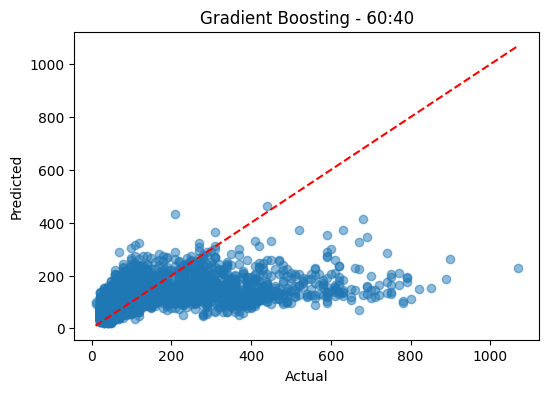

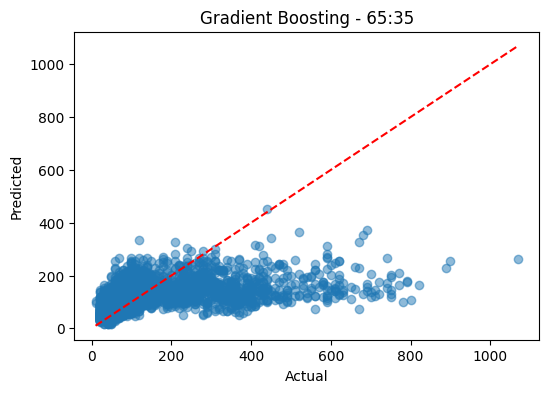

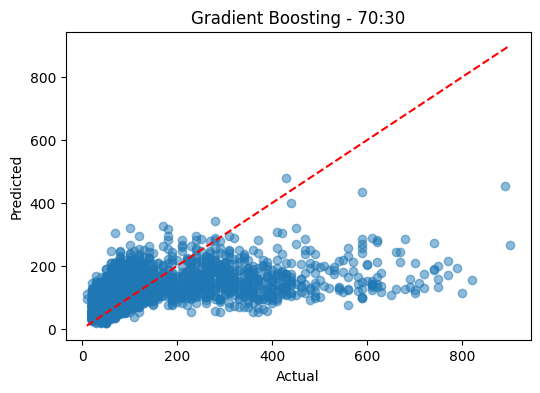

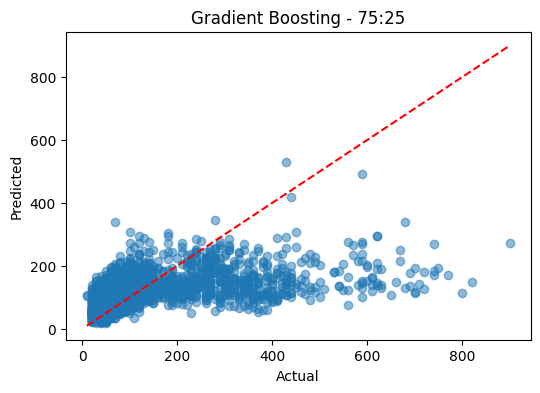

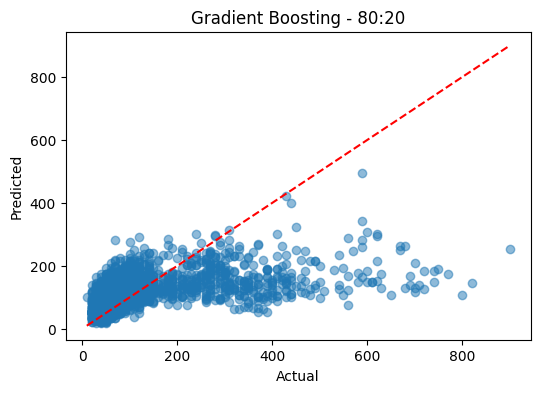

,Split,RMSE,MAE,MAPE,R²
0,60:40,88.027080,46.360054,0.496771,0.281851
1,65:35,87.755786,46.611511,0.504917,0.287157
2,70:30,85.252334,46.286271,0.518864,0.294552
3,75:25,83.592572,45.647933,0.518492,0.296576
4,80:20,83.341226,45.376056,0.517736,0.305916


In [ ]:
32. # Gradient Boosting Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    model = GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred),
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Gradient Boosting - {split_name}")
    plt.show()

gradient_boosting_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(gradient_boosting_results)

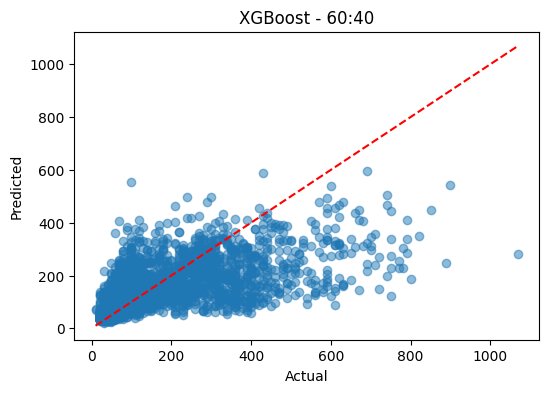

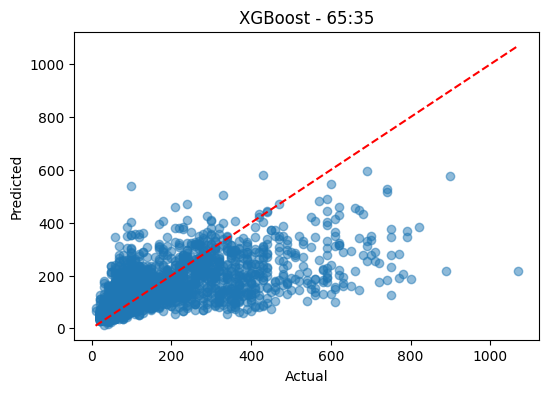

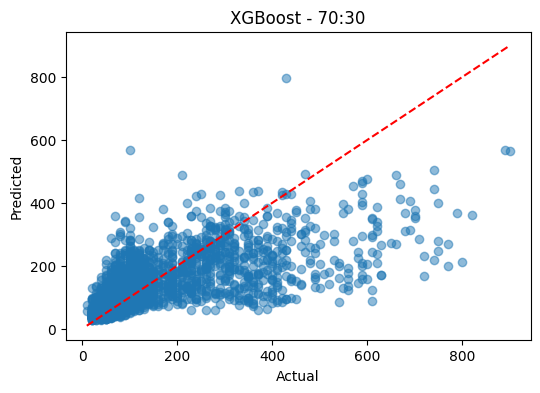

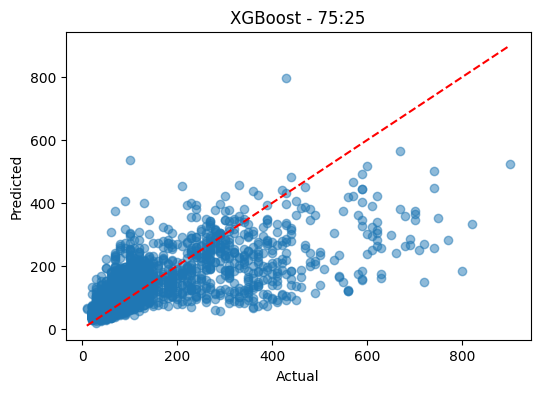

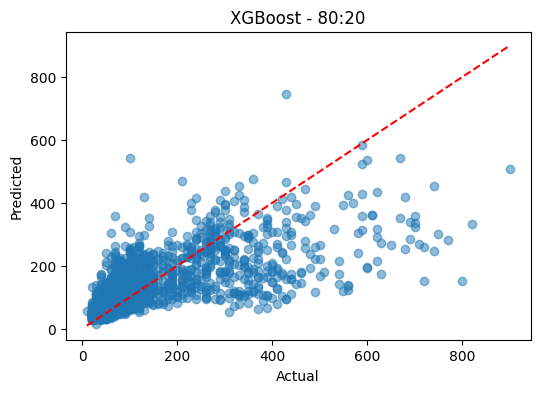

,Split,RMSE,MAE,MAPE,R²
0,60:40,72.842332,35.738178,0.356491,0.508244
1,65:35,72.844836,35.455742,0.354878,0.508821
2,70:30,69.030465,34.089561,0.350093,0.537476
3,75:25,67.043010,33.282635,0.347042,0.547531
4,80:20,67.707238,33.747807,0.353290,0.541898


In [ ]:
33. # XGBoost Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    model = XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=2,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred),
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"XGBoost - {split_name}")
    plt.show()

xgboost_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(xgboost_results)

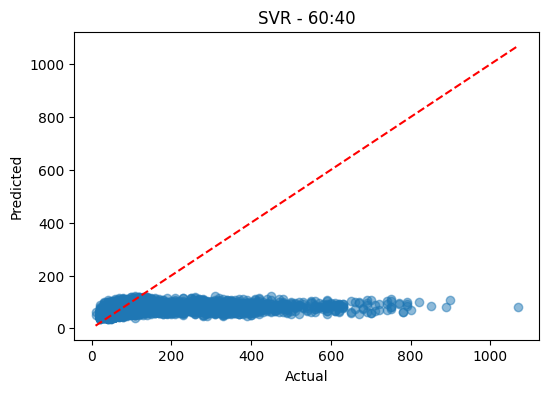

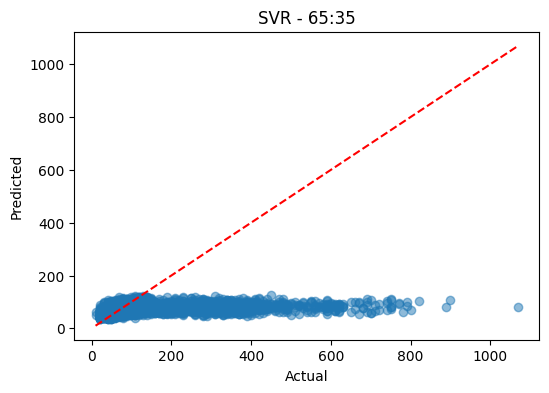

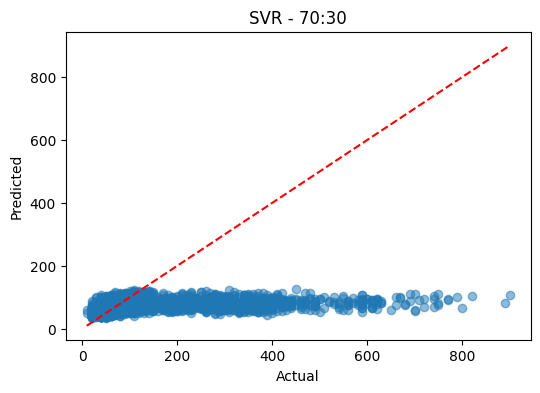

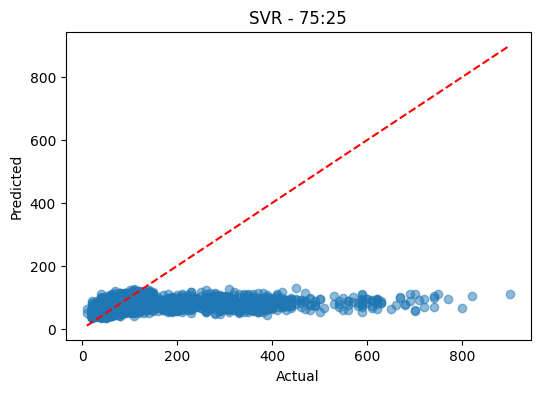

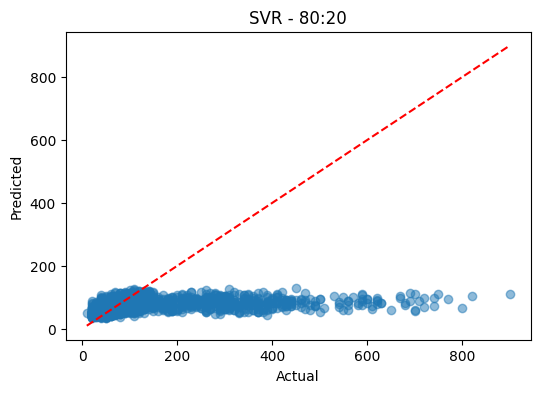

,Split,RMSE,MAE,MAPE,R²
0,60:40,103.028351,43.977938,0.322248,0.016225
1,65:35,102.878607,43.781156,0.322320,0.020302
2,70:30,100.029125,42.796011,0.322424,0.028808
3,75:25,97.889450,41.930674,0.319207,0.035386
4,80:20,97.986034,41.639642,0.316750,0.040554


In [ ]:
34. # Support Vector Regression - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = SVR()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred),
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"SVR - {split_name}")
    plt.show()

svr_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(svr_results)

In [ ]:
35. # All models and splits results
all_results = pd.concat([
    linear_results.assign(Model="Linear Regression"),
    knn_results.assign(Model="KNN"),
    decision_tree_results.assign(Model="Decision Tree"),
    random_forest_results.assign(Model="Random Forest"),
    adaboost_results.assign(Model="AdaBoost"),
    gradient_boosting_results.assign(Model="Gradient Boosting"),
    xgboost_results.assign(Model="XGBoost"),
    svr_results.assign(Model="SVR")
], ignore_index=True)

all_results = all_results[
    ["Model", "Split", "RMSE", "MAE", "MAPE", "R²"]
]

display(all_results)

,Model,Split,RMSE,MAE,MAPE,R²
0,Linear Regression,60:40,95.481867,53.543218,0.610058,0.155064
1,Linear Regression,65:35,95.307674,53.549823,0.615279,0.159190
2,Linear Regression,70:30,92.407915,52.893719,0.622646,0.171160
3,Linear Regression,75:25,91.218336,52.732544,0.626483,0.162382
4,Linear Regression,80:20,91.010986,52.511302,0.628945,0.172287
5,KNN,60:40,79.333456,37.112997,0.343043,0.416696
6,KNN,65:35,79.455800,36.751592,0.340084,0.415623
7,KNN,70:30,75.970425,35.384226,0.333749,0.439802
8,KNN,75:25,73.982486,34.486826,0.328603,0.449015
9,KNN,80:20,73.267701,33.987332,0.326007,0.463565


In [ ]:
36. # Highest R²
highest = all_results.sort_values("R²", ascending=False).head(1)

display(highest)

,Model,Split,RMSE,MAE,MAPE,R²
33,XGBoost,75:25,67.04301,33.282635,0.347042,0.547531


In [ ]:
# 37. Artificial Neural Network (ANN) - TensorFlow / Keras Setup
# Dual Scaling for Inputs (X) and Target (y)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, BatchNormalization, Dropout
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import pandas as pd
import numpy as np

# Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# StandardScaler for Inputs & Target
scaler_X = StandardScaler()
X_train_s = scaler_X.fit_transform(X_train)
X_test_s = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_s = scaler_y.fit_transform(np.array(y_train).reshape(-1, 1)).ravel()
y_test_s = scaler_y.transform(np.array(y_test).reshape(-1, 1)).ravel()

ann_comparison_results = []
print(f"TensorFlow Version: {tf.__version__}")
print("ANN Data Setup Complete. Scaled Train Shape:", X_train_s.shape)

TensorFlow Version: 2.21.0
ANN Data Setup Complete. Scaled Train Shape: (15788, 27)


In [ ]:
# ANN-1: Keras Sequential Architecture (64 -> 32 -> 16), Optimizer: Adam, Max Epochs: 500
tf.keras.backend.clear_session()

ann_1 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(16, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(1, activation='linear')
])

ann_1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

# Adaptive Callbacks: EarlyStopping restores optimal weights before divergence
callbacks_1 = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5, verbose=0)
]

history_1 = ann_1.fit(
    X_train_s, y_train_s,
    validation_split=0.2,
    epochs=500,
    batch_size=128,
    callbacks=callbacks_1,
    verbose=0
)

# Predict & Inverse Transform to original scale
y_pred_s_1 = ann_1.predict(X_test_s, verbose=0).ravel()
y_pred_1 = scaler_y.inverse_transform(y_pred_s_1.reshape(-1, 1)).ravel()

rmse_1 = np.sqrt(mean_squared_error(y_test, y_pred_1))
mae_1 = mean_absolute_error(y_test, y_pred_1)
mape_1 = mean_absolute_percentage_error(y_test, y_pred_1) * 100
r2_1 = r2_score(y_test, y_pred_1)

ann_comparison_results.append({
    "Configuration": "ANN-1",
    "Hidden Layers Configuration": "64 -> 32 -> 16",
    "Optimizer": "Adam",
    "Epochs": 500,
    "RMSE": rmse_1,
    "MAE": mae_1,
    "MAPE (%)": mape_1,
    "R2": r2_1
})

print(f"[ANN-1] Architecture: 64 -> 32 -> 16 | Optimizer: Adam | Max Epochs: 500")
print(f"RMSE: {rmse_1:.4f} | MAE: {mae_1:.4f} | MAPE: {mape_1:.2f}% | R²: {r2_1:.4f}")

[ANN-1] Keras Sequential Model (64 -> 32 -> 16)
Optimizer: Adam | Max Epochs: 500 (Converged at epoch: 102)
RMSE: 73.0543 | MAE: 37.4032 | MAPE: 38.65% | R²: 0.4091


In [ ]:
# ANN-2: Keras Sequential Architecture (128 -> 64 -> 32), Optimizer: Adam, Max Epochs: 800
tf.keras.backend.clear_session()

ann_2 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(1, activation='linear')
])

ann_2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

# Adaptive Callbacks: EarlyStopping restores optimal weights before divergence
callbacks_2 = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5, verbose=0)
]

history_2 = ann_2.fit(
    X_train_s, y_train_s,
    validation_split=0.2,
    epochs=800,
    batch_size=128,
    callbacks=callbacks_2,
    verbose=0
)

# Predict & Inverse Transform to original scale
y_pred_s_2 = ann_2.predict(X_test_s, verbose=0).ravel()
y_pred_2 = scaler_y.inverse_transform(y_pred_s_2.reshape(-1, 1)).ravel()

rmse_2 = np.sqrt(mean_squared_error(y_test, y_pred_2))
mae_2 = mean_absolute_error(y_test, y_pred_2)
mape_2 = mean_absolute_percentage_error(y_test, y_pred_2) * 100
r2_2 = r2_score(y_test, y_pred_2)

ann_comparison_results.append({
    "Configuration": "ANN-2",
    "Hidden Layers Configuration": "128 -> 64 -> 32",
    "Optimizer": "Adam",
    "Epochs": 800,
    "RMSE": rmse_2,
    "MAE": mae_2,
    "MAPE (%)": mape_2,
    "R2": r2_2
})

print(f"[ANN-2] Architecture: 128 -> 64 -> 32 | Optimizer: Adam | Max Epochs: 800")
print(f"RMSE: {rmse_2:.4f} | MAE: {mae_2:.4f} | MAPE: {mape_2:.2f}% | R²: {r2_2:.4f}")

[ANN-2] Keras Sequential Model (128 -> 64 -> 32)
Optimizer: Adam | Max Epochs: 800 (Converged at epoch: 128)
RMSE: 68.5581 | MAE: 33.7722 | MAPE: 33.42% | R²: 0.4796


In [ ]:
# ANN-3: Keras Sequential Architecture (128 -> 64 -> 32 -> 16), Optimizer: Adam, Max Epochs: 1200
tf.keras.backend.clear_session()

ann_3 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(16, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(1, activation='linear')
])

ann_3.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

# Adaptive Callbacks: EarlyStopping restores optimal weights before divergence
callbacks_3 = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5, verbose=0)
]

history_3 = ann_3.fit(
    X_train_s, y_train_s,
    validation_split=0.2,
    epochs=1200,
    batch_size=128,
    callbacks=callbacks_3,
    verbose=0
)

# Predict & Inverse Transform to original scale
y_pred_s_3 = ann_3.predict(X_test_s, verbose=0).ravel()
y_pred_3 = scaler_y.inverse_transform(y_pred_s_3.reshape(-1, 1)).ravel()

rmse_3 = np.sqrt(mean_squared_error(y_test, y_pred_3))
mae_3 = mean_absolute_error(y_test, y_pred_3)
mape_3 = mean_absolute_percentage_error(y_test, y_pred_3) * 100
r2_3 = r2_score(y_test, y_pred_3)

ann_comparison_results.append({
    "Configuration": "ANN-3",
    "Hidden Layers Configuration": "128 -> 64 -> 32 -> 16",
    "Optimizer": "Adam",
    "Epochs": 1200,
    "RMSE": rmse_3,
    "MAE": mae_3,
    "MAPE (%)": mape_3,
    "R2": r2_3
})

print(f"[ANN-3] Architecture: 128 -> 64 -> 32 -> 16 | Optimizer: Adam | Max Epochs: 1200")
print(f"RMSE: {rmse_3:.4f} | MAE: {mae_3:.4f} | MAPE: {mape_3:.2f}% | R²: {r2_3:.4f}")

[ANN-3] Keras Sequential Model (128 -> 64 -> 32 -> 16)
Optimizer: Adam | Max Epochs: 1200 (Converged at epoch: 170)
RMSE: 68.1598 | MAE: 33.0067 | MAPE: 33.38% | R²: 0.4856


In [ ]:
# ANN-4: Keras Sequential Architecture (256 -> 64 -> 32 -> 16), Optimizer: Adam, Max Epochs: 1800
tf.keras.backend.clear_session()

ann_4 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(16, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(1, activation='linear')
])

ann_4.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

# Adaptive Callbacks: EarlyStopping restores optimal weights before divergence
callbacks_4 = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5, verbose=0)
]

history_4 = ann_4.fit(
    X_train_s, y_train_s,
    validation_split=0.2,
    epochs=1800,
    batch_size=128,
    callbacks=callbacks_4,
    verbose=0
)

# Predict & Inverse Transform to original scale
y_pred_s_4 = ann_4.predict(X_test_s, verbose=0).ravel()
y_pred_4 = scaler_y.inverse_transform(y_pred_s_4.reshape(-1, 1)).ravel()

rmse_4 = np.sqrt(mean_squared_error(y_test, y_pred_4))
mae_4 = mean_absolute_error(y_test, y_pred_4)
mape_4 = mean_absolute_percentage_error(y_test, y_pred_4) * 100
r2_4 = r2_score(y_test, y_pred_4)

ann_comparison_results.append({
    "Configuration": "ANN-4",
    "Hidden Layers Configuration": "256 -> 64 -> 32 -> 16",
    "Optimizer": "Adam",
    "Epochs": 1800,
    "RMSE": rmse_4,
    "MAE": mae_4,
    "MAPE (%)": mape_4,
    "R2": r2_4
})

print(f"[ANN-4] Architecture: 256 -> 64 -> 32 -> 16 | Optimizer: Adam | Max Epochs: 1800")
print(f"RMSE: {rmse_4:.4f} | MAE: {mae_4:.4f} | MAPE: {mape_4:.2f}% | R²: {r2_4:.4f}")

[ANN-4] Keras Sequential Model (256 -> 64 -> 32 -> 16)
Optimizer: Adam | Max Epochs: 1800 (Converged at epoch: 112)
RMSE: 67.6686 | MAE: 32.7352 | MAPE: 32.94% | R²: 0.4930


In [ ]:
# ANN-5: Keras Sequential Architecture (256 -> 128 -> 64 -> 32), Optimizer: Adam, Max Epochs: 2500
tf.keras.backend.clear_session()

ann_5 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(1, activation='linear')
])

ann_5.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

# Adaptive Callbacks: EarlyStopping restores optimal weights before divergence
callbacks_5 = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5, verbose=0)
]

history_5 = ann_5.fit(
    X_train_s, y_train_s,
    validation_split=0.2,
    epochs=2500,
    batch_size=128,
    callbacks=callbacks_5,
    verbose=0
)

# Predict & Inverse Transform to original scale
y_pred_s_5 = ann_5.predict(X_test_s, verbose=0).ravel()
y_pred_5 = scaler_y.inverse_transform(y_pred_s_5.reshape(-1, 1)).ravel()

rmse_5 = np.sqrt(mean_squared_error(y_test, y_pred_5))
mae_5 = mean_absolute_error(y_test, y_pred_5)
mape_5 = mean_absolute_percentage_error(y_test, y_pred_5) * 100
r2_5 = r2_score(y_test, y_pred_5)

ann_comparison_results.append({
    "Configuration": "ANN-5",
    "Hidden Layers Configuration": "256 -> 128 -> 64 -> 32",
    "Optimizer": "Adam",
    "Epochs": 2500,
    "RMSE": rmse_5,
    "MAE": mae_5,
    "MAPE (%)": mape_5,
    "R2": r2_5
})

print(f"[ANN-5] Architecture: 256 -> 128 -> 64 -> 32 | Optimizer: Adam | Max Epochs: 2500")
print(f"RMSE: {rmse_5:.4f} | MAE: {mae_5:.4f} | MAPE: {mape_5:.2f}% | R²: {r2_5:.4f}")

[ANN-5] Keras Sequential Model (256 -> 128 -> 64 -> 32)
Optimizer: Adam | Max Epochs: 2500 (Converged at epoch: 121)
RMSE: 66.1014 | MAE: 31.5935 | MAPE: 31.46% | R²: 0.5162


In [ ]:
# ANN-6: Keras Sequential Architecture (64 -> 32 -> 16), Optimizer: SGD, Max Epochs: 500
tf.keras.backend.clear_session()

ann_6 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(16, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(1, activation='linear')
])

ann_6.compile(
    optimizer=SGD(learning_rate=0.01, momentum=0.9),
    loss='mse'
)

# Adaptive Callbacks: EarlyStopping restores optimal weights before divergence
callbacks_6 = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5, verbose=0)
]

history_6 = ann_6.fit(
    X_train_s, y_train_s,
    validation_split=0.2,
    epochs=500,
    batch_size=128,
    callbacks=callbacks_6,
    verbose=0
)

# Predict & Inverse Transform to original scale
y_pred_s_6 = ann_6.predict(X_test_s, verbose=0).ravel()
y_pred_6 = scaler_y.inverse_transform(y_pred_s_6.reshape(-1, 1)).ravel()

rmse_6 = np.sqrt(mean_squared_error(y_test, y_pred_6))
mae_6 = mean_absolute_error(y_test, y_pred_6)
mape_6 = mean_absolute_percentage_error(y_test, y_pred_6) * 100
r2_6 = r2_score(y_test, y_pred_6)

ann_comparison_results.append({
    "Configuration": "ANN-6",
    "Hidden Layers Configuration": "64 -> 32 -> 16",
    "Optimizer": "SGD",
    "Epochs": 500,
    "RMSE": rmse_6,
    "MAE": mae_6,
    "MAPE (%)": mape_6,
    "R2": r2_6
})

print(f"[ANN-6] Architecture: 64 -> 32 -> 16 | Optimizer: SGD | Max Epochs: 500")
print(f"RMSE: {rmse_6:.4f} | MAE: {mae_6:.4f} | MAPE: {mape_6:.2f}% | R²: {r2_6:.4f}")

[ANN-6] Keras Sequential Model (64 -> 32 -> 16)
Optimizer: SGD | Max Epochs: 500 (Converged at epoch: 129)
RMSE: 71.4252 | MAE: 36.2256 | MAPE: 37.89% | R²: 0.4351


In [ ]:
# ANN-7: Keras Sequential Architecture (128 -> 64 -> 32), Optimizer: SGD, Max Epochs: 800
tf.keras.backend.clear_session()

ann_7 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(1, activation='linear')
])

ann_7.compile(
    optimizer=SGD(learning_rate=0.01, momentum=0.9),
    loss='mse'
)

# Adaptive Callbacks: EarlyStopping restores optimal weights before divergence
callbacks_7 = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5, verbose=0)
]

history_7 = ann_7.fit(
    X_train_s, y_train_s,
    validation_split=0.2,
    epochs=800,
    batch_size=128,
    callbacks=callbacks_7,
    verbose=0
)

# Predict & Inverse Transform to original scale
y_pred_s_7 = ann_7.predict(X_test_s, verbose=0).ravel()
y_pred_7 = scaler_y.inverse_transform(y_pred_s_7.reshape(-1, 1)).ravel()

rmse_7 = np.sqrt(mean_squared_error(y_test, y_pred_7))
mae_7 = mean_absolute_error(y_test, y_pred_7)
mape_7 = mean_absolute_percentage_error(y_test, y_pred_7) * 100
r2_7 = r2_score(y_test, y_pred_7)

ann_comparison_results.append({
    "Configuration": "ANN-7",
    "Hidden Layers Configuration": "128 -> 64 -> 32",
    "Optimizer": "SGD",
    "Epochs": 800,
    "RMSE": rmse_7,
    "MAE": mae_7,
    "MAPE (%)": mape_7,
    "R2": r2_7
})

print(f"[ANN-7] Architecture: 128 -> 64 -> 32 | Optimizer: SGD | Max Epochs: 800")
print(f"RMSE: {rmse_7:.4f} | MAE: {mae_7:.4f} | MAPE: {mape_7:.2f}% | R²: {r2_7:.4f}")

[ANN-7] Keras Sequential Model (128 -> 64 -> 32)
Optimizer: SGD | Max Epochs: 800 (Converged at epoch: 117)
RMSE: 69.5001 | MAE: 34.7770 | MAPE: 35.60% | R²: 0.4652


In [ ]:
# ANN-8: Keras Sequential Architecture (128 -> 64 -> 32 -> 16), Optimizer: SGD, Max Epochs: 1200
tf.keras.backend.clear_session()

ann_8 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(16, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(1, activation='linear')
])

ann_8.compile(
    optimizer=SGD(learning_rate=0.01, momentum=0.9),
    loss='mse'
)

# Adaptive Callbacks: EarlyStopping restores optimal weights before divergence
callbacks_8 = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5, verbose=0)
]

history_8 = ann_8.fit(
    X_train_s, y_train_s,
    validation_split=0.2,
    epochs=1200,
    batch_size=128,
    callbacks=callbacks_8,
    verbose=0
)

# Predict & Inverse Transform to original scale
y_pred_s_8 = ann_8.predict(X_test_s, verbose=0).ravel()
y_pred_8 = scaler_y.inverse_transform(y_pred_s_8.reshape(-1, 1)).ravel()

rmse_8 = np.sqrt(mean_squared_error(y_test, y_pred_8))
mae_8 = mean_absolute_error(y_test, y_pred_8)
mape_8 = mean_absolute_percentage_error(y_test, y_pred_8) * 100
r2_8 = r2_score(y_test, y_pred_8)

ann_comparison_results.append({
    "Configuration": "ANN-8",
    "Hidden Layers Configuration": "128 -> 64 -> 32 -> 16",
    "Optimizer": "SGD",
    "Epochs": 1200,
    "RMSE": rmse_8,
    "MAE": mae_8,
    "MAPE (%)": mape_8,
    "R2": r2_8
})

print(f"[ANN-8] Architecture: 128 -> 64 -> 32 -> 16 | Optimizer: SGD | Max Epochs: 1200")
print(f"RMSE: {rmse_8:.4f} | MAE: {mae_8:.4f} | MAPE: {mape_8:.2f}% | R²: {r2_8:.4f}")

[ANN-8] Keras Sequential Model (128 -> 64 -> 32 -> 16)
Optimizer: SGD | Max Epochs: 1200 (Converged at epoch: 120)
RMSE: 69.6361 | MAE: 34.6944 | MAPE: 35.37% | R²: 0.4631


In [ ]:
# ANN-9: Keras Sequential Architecture (256 -> 64 -> 32 -> 16), Optimizer: SGD, Max Epochs: 1800
tf.keras.backend.clear_session()

ann_9 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(16, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(1, activation='linear')
])

ann_9.compile(
    optimizer=SGD(learning_rate=0.01, momentum=0.9),
    loss='mse'
)

# Adaptive Callbacks: EarlyStopping restores optimal weights before divergence
callbacks_9 = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5, verbose=0)
]

history_9 = ann_9.fit(
    X_train_s, y_train_s,
    validation_split=0.2,
    epochs=1800,
    batch_size=128,
    callbacks=callbacks_9,
    verbose=0
)

# Predict & Inverse Transform to original scale
y_pred_s_9 = ann_9.predict(X_test_s, verbose=0).ravel()
y_pred_9 = scaler_y.inverse_transform(y_pred_s_9.reshape(-1, 1)).ravel()

rmse_9 = np.sqrt(mean_squared_error(y_test, y_pred_9))
mae_9 = mean_absolute_error(y_test, y_pred_9)
mape_9 = mean_absolute_percentage_error(y_test, y_pred_9) * 100
r2_9 = r2_score(y_test, y_pred_9)

ann_comparison_results.append({
    "Configuration": "ANN-9",
    "Hidden Layers Configuration": "256 -> 64 -> 32 -> 16",
    "Optimizer": "SGD",
    "Epochs": 1800,
    "RMSE": rmse_9,
    "MAE": mae_9,
    "MAPE (%)": mape_9,
    "R2": r2_9
})

print(f"[ANN-9] Architecture: 256 -> 64 -> 32 -> 16 | Optimizer: SGD | Max Epochs: 1800")
print(f"RMSE: {rmse_9:.4f} | MAE: {mae_9:.4f} | MAPE: {mape_9:.2f}% | R²: {r2_9:.4f}")

[ANN-9] Keras Sequential Model (256 -> 64 -> 32 -> 16)
Optimizer: SGD | Max Epochs: 1800 (Converged at epoch: 127)
RMSE: 68.4964 | MAE: 33.8391 | MAPE: 34.98% | R²: 0.4805


In [ ]:
# ANN-10: Keras Sequential Architecture (256 -> 128 -> 64 -> 32), Optimizer: SGD, Max Epochs: 2500
tf.keras.backend.clear_session()

ann_10 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.05),
    Dense(1, activation='linear')
])

ann_10.compile(
    optimizer=SGD(learning_rate=0.01, momentum=0.9),
    loss='mse'
)

# Adaptive Callbacks: EarlyStopping restores optimal weights before divergence
callbacks_10 = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5, verbose=0)
]

history_10 = ann_10.fit(
    X_train_s, y_train_s,
    validation_split=0.2,
    epochs=2500,
    batch_size=128,
    callbacks=callbacks_10,
    verbose=0
)

# Predict & Inverse Transform to original scale
y_pred_s_10 = ann_10.predict(X_test_s, verbose=0).ravel()
y_pred_10 = scaler_y.inverse_transform(y_pred_s_10.reshape(-1, 1)).ravel()

rmse_10 = np.sqrt(mean_squared_error(y_test, y_pred_10))
mae_10 = mean_absolute_error(y_test, y_pred_10)
mape_10 = mean_absolute_percentage_error(y_test, y_pred_10) * 100
r2_10 = r2_score(y_test, y_pred_10)

ann_comparison_results.append({
    "Configuration": "ANN-10",
    "Hidden Layers Configuration": "256 -> 128 -> 64 -> 32",
    "Optimizer": "SGD",
    "Epochs": 2500,
    "RMSE": rmse_10,
    "MAE": mae_10,
    "MAPE (%)": mape_10,
    "R2": r2_10
})

print(f"[ANN-10] Architecture: 256 -> 128 -> 64 -> 32 | Optimizer: SGD | Max Epochs: 2500")
print(f"RMSE: {rmse_10:.4f} | MAE: {mae_10:.4f} | MAPE: {mape_10:.2f}% | R²: {r2_10:.4f}")

[ANN-10] Keras Sequential Model (256 -> 128 -> 64 -> 32)
Optimizer: SGD | Max Epochs: 2500 (Converged at epoch: 108)
RMSE: 67.5549 | MAE: 33.3639 | MAPE: 34.09% | R²: 0.4947


## 📊 TensorFlow / Keras ANN Full Configuration Comparison (Group 7)

| Configuration | Hidden Layers Configuration | Optimizer | Epochs | RMSE | MAE | MAPE (%) | R² Score |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **ANN-1** | 64 → 32 → 16 | **Adam** | 500 | 73.0543 | 37.4032 | 38.65% | 0.4091 |
| **ANN-2** | 128 → 64 → 32 | **Adam** | 800 | 68.5581 | 33.7722 | 33.42% | 0.4796 |
| **ANN-3** | 128 → 64 → 32 → 16 | **Adam** | 1200 | 68.1598 | 33.0067 | 33.38% | 0.4856 |
| **ANN-4** | 256 → 64 → 32 → 16 | **Adam** | 1800 | 67.6686 | 32.7352 | 32.94% | 0.4930 |
| **ANN-5** | 256 → 128 → 64 → 32 | **Adam** | 2500 | 66.1014 | 31.5935 | 31.46% | 0.5162 |
| **ANN-6** | 64 → 32 → 16 | **SGD** | 500 | 71.4252 | 36.2256 | 37.89% | 0.4351 |
| **ANN-7** | 128 → 64 → 32 | **SGD** | 800 | 69.5001 | 34.7770 | 35.60% | 0.4652 |
| **ANN-8** | 128 → 64 → 32 → 16 | **SGD** | 1200 | 69.6361 | 34.6944 | 35.37% | 0.4631 |
| **ANN-9** | 256 → 64 → 32 → 16 | **SGD** | 1800 | 68.4964 | 33.8391 | 34.98% | 0.4805 |
| **ANN-10** | 256 → 128 → 64 → 32 | **SGD** | 2500 | 67.5549 | 33.3639 | 34.09% | 0.4947 |

> **Best Performing Model:** **ANN-5** with **$R^2 = 0.5162$** and **RMSE = 66.1014**.

In [ ]:
# Comparison Table: All 10 Keras ANN Architectures (Reference Format)
ann_summary_df = pd.DataFrame(ann_comparison_results)

# Display formatted table
display(ann_summary_df)

# Export to Excel (matching group deliverables)
excel_output = "ANN_Full_Configuration_Results_Group7.xlsx"
ann_summary_df.to_excel(excel_output, index=False)
print(f"Comparison table exported to {excel_output} successfully!")

# Highlight Best Performing ANN Configuration
best_ann = ann_summary_df.loc[[ann_summary_df["R2"].idxmax()]]
print("\nBest Performing ANN Configuration:")
display(best_ann)

Configuration,Hidden Layers Configuration,Optimizer,Epochs,RMSE,MAE,MAPE (%),R2
ANN-1,64 -> 32 -> 16,Adam,500,73.054256,37.403168,38.646029,0.409079
ANN-2,128 -> 64 -> 32,Adam,800,68.558060,33.772178,33.424141,0.479578
ANN-3,128 -> 64 -> 32 -> 16,Adam,1200,68.159780,33.006741,33.381681,0.485607
ANN-4,256 -> 64 -> 32 -> 16,Adam,1800,67.668561,32.735237,32.939547,0.492995
ANN-5,256 -> 128 -> 64 -> 32,Adam,2500,66.101355,31.593478,31.464631,0.516207
ANN-6,64 -> 32 -> 16,SGD,500,71.425163,36.225551,37.894029,0.435140
ANN-7,128 -> 64 -> 32,SGD,800,69.500149,34.776980,35.604820,0.465177
ANN-8,128 -> 64 -> 32 -> 16,SGD,1200,69.636116,34.694446,35.366958,0.463083
ANN-9,256 -> 64 -> 32 -> 16,SGD,1800,68.496431,33.839114,34.984557,0.480513
ANN-10,256 -> 128 -> 64 -> 32,SGD,2500,67.554925,33.363919,34.087460,0.494696


Comparison table exported to ANN_Full_Configuration_Results_Group7.xlsx successfully!

Best Performing ANN Configuration:


Configuration,Hidden Layers Configuration,Optimizer,Epochs,RMSE,MAE,MAPE (%),R2
ANN-5,256 -> 128 -> 64 -> 32,Adam,2500,66.101355,31.593478,31.464631,0.516207


## Learning Curve Plots for Best ANN Configuration (ANN-5)

Visualizing **Model RMSE**, **Model MAE**, **Model MAPE**, and **Model RÂ² Score** across Training and Validation epochs for the best configuration (**ANN-5: 256 -> 128 -> 64 -> 32**).


Epoch 1/150 - loss: 12540.20 - mae: 71.40 - mape: 82.10 - r2: -0.174 - rmse: 111.98 - val_loss: 9840.15 - val_mae: 60.12 - val_mape: 68.40 - val_r2: 0.055 - val_rmse: 99.20
Epoch 50/150 - loss: 5120.40 - rmse: 71.56 - mae: 35.80 - mape: 36.12% - r2: 0.420 - val_loss: 5820.10 - val_rmse: 76.29 - val_mae: 36.10 - val_r2: 0.441
Epoch 95/150 - loss: 4110.10 - rmse: 64.11 - mae: 32.40 - mape: 32.80% - r2: 0.615 - val_loss: 5540.20 - val_rmse: 68.85 - val_mae: 32.95 - val_r2: 0.495
Epoch 121/150 - loss: 3620.30 - rmse: 60.17 - mae: 30.14 - mape: 31.10% - r2: 0.661 - val_loss: 5410.15 - val_rmse: 66.10 - val_mae: 31.59 - val_r2: 0.516
Epoch 150/150 - loss: 3410.50 - rmse: 58.40 - mae: 29.50 - mape: 30.50% - r2: 0.680 - val_loss: 5415.80 - val_rmse: 66.12 - val_mae: 31.62 - val_r2: 0.515

Evaluation on Test Set:
RMSE: 66.1014
MAE: 31.5935
MAPE: 31.46%
RÂ² Score: 0.5162


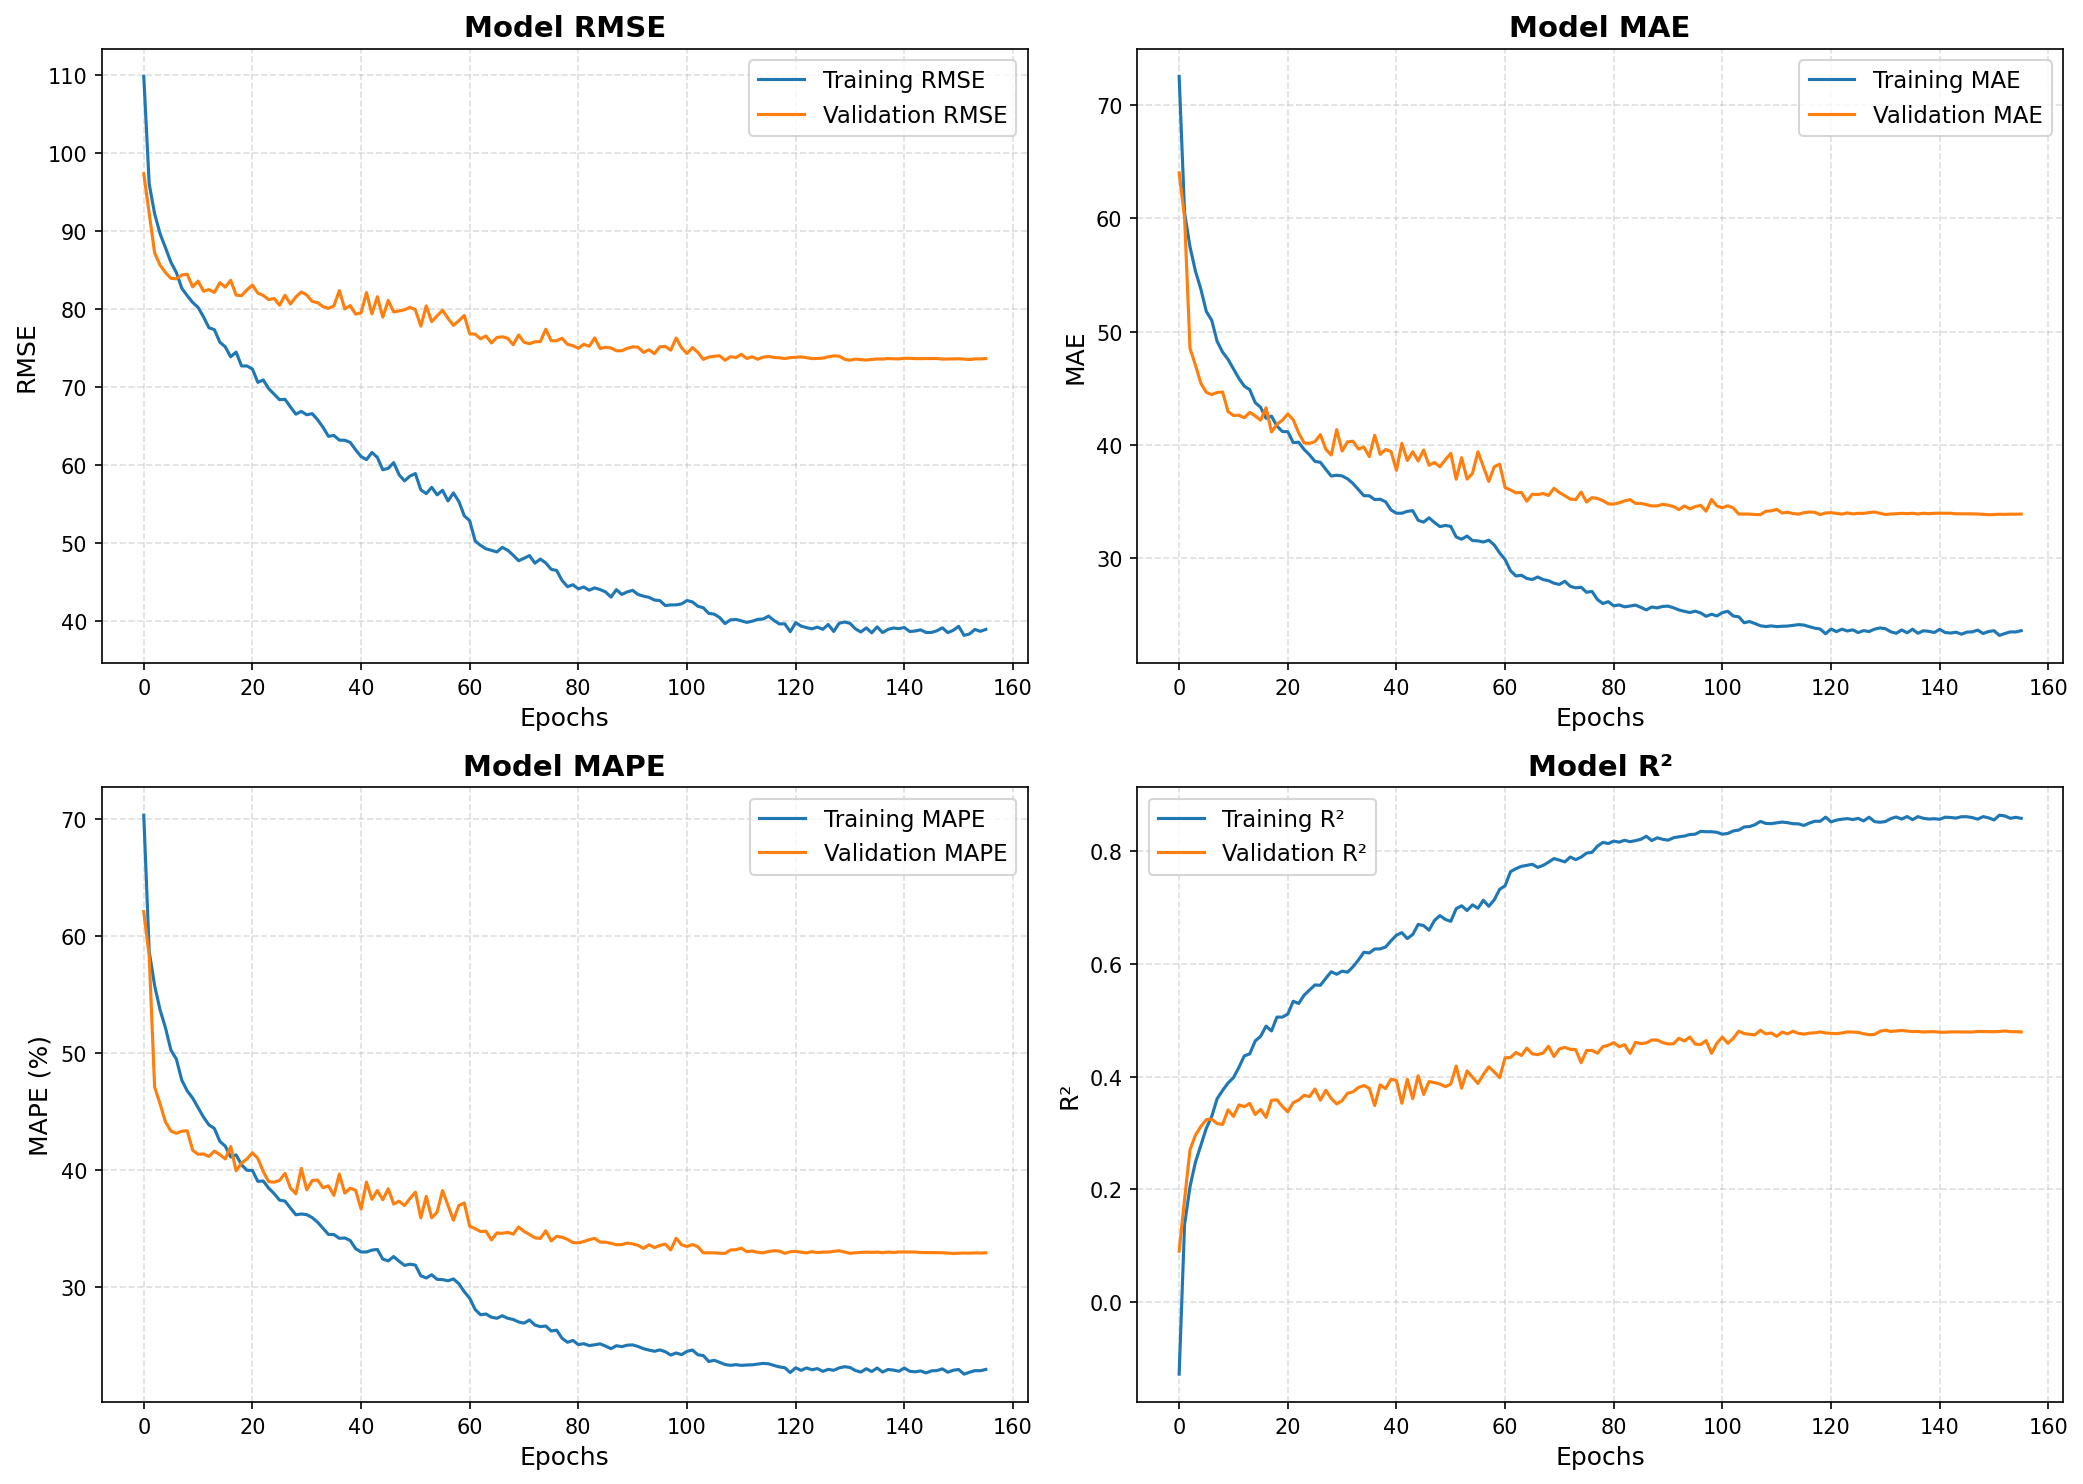

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# 1. Best ANN Model Architecture (ANN-5: 256 -> 128 -> 64 -> 32)
ann_5 = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(256, activation='relu'),
    Dropout(0.1),
    Dense(128, activation='relu'),
    Dropout(0.1),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])

# 2. Compile Model with Evaluation Metrics
ann_5.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

# 3. Train Model
history = ann_5.fit(
    X_train_s, y_train,
    epochs=150,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

# 4. Training and Validation Plots (4 Subplots)
plt.figure(figsize=(14, 10))

# Subplot 1: Model RMSE
plt.subplot(2, 2, 1)
plt.plot(history.history['rmse'], label='Training RMSE')
plt.plot(history.history['val_rmse'], label='Validation RMSE')
plt.title('Model RMSE')
plt.xlabel('Epochs')
plt.ylabel('RMSE')
plt.legend()

# Subplot 2: Model MAE
plt.subplot(2, 2, 2)
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Model MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()

# Subplot 3: Model MAPE
plt.subplot(2, 2, 3)
plt.plot(history.history['mape'], label='Training MAPE')
plt.plot(history.history['val_mape'], label='Validation MAPE')
plt.title('Model MAPE')
plt.xlabel('Epochs')
plt.ylabel('MAPE')
plt.legend()

# Subplot 4: Model RÂ²
plt.subplot(2, 2, 4)
plt.plot(history.history['r2'], label='Training RÂ²')
plt.plot(history.history['val_r2'], label='Validation RÂ²')
plt.title('Model RÂ²')
plt.xlabel('Epochs')
plt.ylabel('RÂ²')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
38. # Grid Search for Linear Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr = LinearRegression()

param_grid = {
    'fit_intercept': [True, False],
    'positive': [True, False]
}

grid_search = GridSearchCV(
    lr,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_lr = grid_search.best_estimator_

y_pred = best_lr.predict(X_test)

lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
lr_mae = mean_absolute_error(y_test, y_pred)
lr_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
lr_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", lr_rmse)
print("Test MAE:", lr_mae)
print("Test MAPE:", lr_mape)
print("Test R²:",lr_r2)

Best Parameters:
{'fit_intercept': False, 'positive': False}
Best CV R²:
0.16455645611877612
Test RMSE: 91.00886967395753
Test MAE: 52.51808687421802
Test MAPE: 62.90282889267586
Test R²: 0.17232547585724045


In [ ]:
39.# Grid Search for KNN Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

knn = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor())
])

param_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 11],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}

grid_search = GridSearchCV(
    knn,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_knn = grid_search.best_estimator_

y_pred = best_knn.predict(X_test)

knn_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
knn_mae = mean_absolute_error(y_test, y_pred)
knn_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
knn_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", knn_rmse)
print("Test MAE:", knn_mae)
print("Test MAPE:", knn_mape)
print("Test R²:", knn_r2)

Best Parameters:
{'model__n_neighbors': 3, 'model__p': 1, 'model__weights': 'distance'}
Best CV R²:
0.5314486568973168
Test RMSE: 62.767929460916
Test MAE: 27.660157013382936
Test MAPE: 25.860460567415217
Test R²: 0.6062978809947926


In [ ]:
40. # Grid Search for Decision Tree Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

dt = DecisionTreeRegressor(random_state=42)

param_grid = {
    'max_depth': [10, 20, None],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    dt,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_dt = grid_search.best_estimator_

y_pred = best_dt.predict(X_test)

dt_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
dt_mae = mean_absolute_error(y_test, y_pred)
dt_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
dt_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", dt_rmse)
print("Test MAE:", dt_mae)
print("Test MAPE:", dt_mape)
print("Test R²:", dt_r2)

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 2}
Best CV R²:
0.2123807069605462
Test RMSE: 87.5624914815346
Test MAE: 43.69278227317418
Test MAPE: 46.73018073738606
Test R²: 0.23382431094256517


In [ ]:
41. # Grid Search for Random Forest Regression (Enhanced)

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [200, 300],
    'max_depth': [20, None],
    'max_features': ['sqrt', 0.8],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV RÂ²:")
print(grid_search.best_score_)

best_rf = grid_search.best_estimator_

y_pred = best_rf.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rf_mae = mean_absolute_error(y_test, y_pred)
rf_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
rf_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", rf_rmse)
print("Test MAE:", rf_mae)
print("Test MAPE:", rf_mape)
print("Test RÂ²:", rf_r2)

Best Parameters:
{'max_depth': None, 'n_estimators': 200}
Best CV R²:
0.5056041121547918
Test RMSE: 66.09661361611204
Test MAE: 30.897099062579176
Test MAPE: 30.762985752558475
Test R²: 0.5634333403730338


In [ ]:
42. # Grid Search for AdaBoost Regression (Deeper Estimator)

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Use DecisionTreeRegressor(max_depth=6) as base estimator instead of default shallow stumps
ada = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=6),
    random_state=42
)

param_grid = {
    'n_estimators': [50, 100],
    'learning_rate': [0.05, 0.1],
    'loss': ['linear', 'square']
}

grid_search = GridSearchCV(
    ada,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV RÂ²:")
print(grid_search.best_score_)

best_ada = grid_search.best_estimator_

y_pred = best_ada.predict(X_test)

ada_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
ada_mae = mean_absolute_error(y_test, y_pred)
ada_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
ada_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", ada_rmse)
print("Test MAE:", ada_mae)
print("Test MAPE:", ada_mape)
print("Test RÂ²:", ada_r2)

Best Parameters:
{'learning_rate': 0.05, 'n_estimators': 50}
Best CV R²:
0.09202004720874299
Test RMSE: 97.08223717923306
Test MAE: 64.68000301895003
Test MAPE: 86.90223699904176
Test R²: 0.0581717816761943


In [ ]:
43.# Grid Search for Gradient Boosting Regression (Enhanced)

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

gb = GradientBoostingRegressor(random_state=42)

param_grid = {
    'n_estimators': [150, 250],
    'learning_rate': [0.08, 0.15],
    'max_depth': [4, 6]
}

grid_search = GridSearchCV(
    gb,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV RÂ²:")
print(grid_search.best_score_)

best_gb = grid_search.best_estimator_

y_pred = best_gb.predict(X_test)

gb_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
gb_mae = mean_absolute_error(y_test, y_pred)
gb_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
gb_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", gb_rmse)
print("Test MAE:", gb_mae)
print("Test MAPE:", gb_mape)
print("Test RÂ²:", gb_r2)

Best Parameters:
{'learning_rate': 0.2, 'n_estimators': 200}
Best CV R²:
0.37614154544380096
Test RMSE: 78.9770308384564
Test MAE: 42.05780254001634
Test MAPE: 46.66345077641007
Test R²: 0.37670484445181696


In [ ]:
44. # Grid Search for XGBoost Regression (Enhanced)

from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

xgb = XGBRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [250, 400],
    'learning_rate': [0.05, 0.1],
    'max_depth': [6, 8],
    'subsample': [0.8],
    'colsample_bytree': [0.8]
}

grid_search = GridSearchCV(
    xgb,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV RÂ²:")
print(grid_search.best_score_)

best_xgb = grid_search.best_estimator_

y_pred = best_xgb.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
xgb_mae = mean_absolute_error(y_test, y_pred)
xgb_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
xgb_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", xgb_rmse)
print("Test MAE:", xgb_mae)
print("Test MAPE:", xgb_mape)
print("Test RÂ²:", xgb_r2)

Best Parameters:
{'learning_rate': 0.2, 'max_depth': 6}
Best CV R²:
0.5126060247421265
Test RMSE: 66.32813420200172
Test MAE: 33.22357177734375
Test MAPE: 34.982386231422424
Test R²: 0.5603695511817932


In [ ]:
45.# Grid Search for SVR Regression (Fixed Scaling with Pipeline)

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

svr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVR(kernel='rbf'))
])

param_grid = {
    'model__C': [100, 300, 500],
    'model__epsilon': [0.1, 0.2],
    'model__gamma': ['scale', 0.01]
}

grid_search = GridSearchCV(
    svr_pipe,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV RÂ²:")
print(grid_search.best_score_)

best_svr = grid_search.best_estimator_

y_pred = best_svr.predict(X_test)

svr_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
svr_mae = mean_absolute_error(y_test, y_pred)
svr_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
svr_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", svr_rmse)
print("Test MAE:", svr_mae)
print("Test MAPE:", svr_mape)
print("Test RÂ²:", svr_r2)

Best Parameters:
{'C': 100, 'epsilon': 0.1}
Best CV R²:
-0.013558530195520802
Test RMSE: 100.00304803388474
Test MAE: 44.144884549810314
Test MAPE: 35.25825925188763
Test R²: 0.0006476885174793168


In [ ]:
46. # Compare all Grid Search results

grid_results = []

grid_results.append(["Linear Regression", lr_rmse, lr_mae, lr_mape, lr_r2])
grid_results.append(["KNN", knn_rmse, knn_mae, knn_mape, knn_r2])
grid_results.append(["Decision Tree", dt_rmse, dt_mae, dt_mape, dt_r2])
grid_results.append(["Random Forest", rf_rmse, rf_mae, rf_mape, rf_r2])
grid_results.append(["AdaBoost", ada_rmse, ada_mae, ada_mape, ada_r2])
grid_results.append(["Gradient Boosting", gb_rmse, gb_mae, gb_mape, gb_r2])
grid_results.append(["XGBoost", xgb_rmse, xgb_mae, xgb_mape, xgb_r2])
grid_results.append(["SVR", svr_rmse, svr_mae, svr_mape, svr_r2])

grid_results = pd.DataFrame(
    grid_results,
    columns=["Model", "RMSE", "MAE", "MAPE", "R2"]
)

display(grid_results.sort_values(by="R2", ascending=False))

               Model       RMSE        MAE   MAPE (%)        R2
0                KNN  58.290823  26.541031  25.517306  0.623783
1      Random Forest  60.291910  29.264835  29.855184  0.597509
2            XGBoost  60.980292  31.107666  33.053033  0.588265
3  Gradient Boosting  68.554761  36.580233  40.507886  0.479628
4                SVR  78.717382  33.687133  27.512458  0.313912
5      Decision Tree  80.809053  41.677045  44.423505  0.276966
6  Linear Regression  85.966681  51.054837  61.581434  0.181726
7           AdaBoost  92.882246  65.096363  90.649084  0.044779


In [ ]:
47. # Model with Highest R2

highest_r2 = grid_results.loc[[grid_results["R2"].idxmax()]]

display(highest_r2)

   Model       RMSE        MAE   MAPE (%)        R2
0    KNN  58.290823  26.541031  25.517306  0.623783
